# Лабораторная работа №14: Управляемая генерация изображений

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Получить canny/depth/pose controls.
- Сравнить control scale и CFG.
- Использовать control как synthetic annotation для downstream model.

## Теоретическая часть

ControlNet добавляет trainable branch к замороженной diffusion model и принимает spatial condition (edges, depth, pose). В лабораторной используется готовый ControlNet; изменяются conditioning scale и CFG.

![Пример результата ControlNet с Canny-контролем](https://huggingface.co/lllyasviel/sd-controlnet-canny/resolve/main/images/bird_canny_out.png)


Готовый ControlNet добавляет пространственное условие к SD1.5. В работе контур Canny вычисляется только из train MNIST; тот же исходный label сопровождает synthetic image. Edge F1, CLIP text similarity и downstream accuracy на реальном test отражают разные свойства и могут конфликтовать.

Для контуров $F_1=2PR/(P+R)$; допустимое геометрическое отклонение задаётся расширением контуров до расчёта точности и полноты. Downstream accuracy измеряется только на реальном отложенном test.

### Экспериментальный протокол

Выбрано условие Canny, обучение ControlNet не требуется. Полный режим: 20 train контуров каждого из 10 классов, 5 генераций на контур (base + сетка scale/CFG), отдельный real test и одинаковые 500 optimizer steps каждого downstream classifier. Это дорогой эксперимент: перед запуском оцените лимит Colab, сохраняйте artifacts в Drive; FAST_DEV_RUN генерирует по 1 примеру каждого класса и 2 шага классификатора, только smoke. Нужны CUDA, diffusers transformers accelerate opencv-python torchvision.

### Материалы

- [Diffusers ControlNet](https://huggingface.co/docs/diffusers/using-diffusers/controlnet)
- [ControlNet paper](https://arxiv.org/abs/2302.05543)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch

SEED = 42
FAST_DEV_RUN = False  # True: только проверка связности, не для сдачи

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# У каждой лабы своя папка: artifacts/lab14 — метрики, таблицы, checkpoints;
# data/lab14 — контуры Canny и синтетические генерации этой работы.
# MNIST общий для курса и уже лежит в data/MNIST/raw, поэтому torchvision root = data.
ARTIFACTS = Path(os.getenv('CV_ARTIFACTS', 'artifacts/lab14'))
DATA_ROOT = Path(os.getenv('CV_DATA', 'data/lab14'))
MNIST_ROOT = Path(os.getenv('CV_COURSE_DATA', 'data'))
CONTROL_DIR = DATA_ROOT / 'controls'    # PNG-контуры Canny из train MNIST
SYNTH_DIR = DATA_ROOT / 'synthetic'     # генерации ControlNet (base + сетка scale/CFG)
for folder in (ARTIFACTS, DATA_ROOT, CONTROL_DIR, SYNTH_DIR):
    folder.mkdir(parents=True, exist_ok=True)
# Вычислительный профиль: SD1.5 + готовый ControlNet, FP16 inference (CUDA обязательна, CPU-имитация недопустима).
# Сокращённый режим — 256–384 px и sequential CPU offload: FAST_DEV_RUN -> 256 px,
# мало VRAM (< 10 ГБ или CV_LOW_VRAM=1) -> 384 px + offload, иначе полный режим 512 px на GPU.
DTYPE = torch.float16
VRAM_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if torch.cuda.is_available() else 0.0
LOW_VRAM = os.getenv('CV_LOW_VRAM', '0') == '1' or VRAM_GB < 10
SEQUENTIAL_OFFLOAD = FAST_DEV_RUN or LOW_VRAM
RESOLUTION = 256 if FAST_DEV_RUN else (384 if LOW_VRAM else 512)
NOTEBOOK_T0 = time.time()  # начало прогона — для итогового run_info.json

def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    text = json.dumps(value, ensure_ascii=False, indent=2, default=str)
    destination.write_text(text, encoding='utf-8')

print({'device': DEVICE, 'fast_dev_run': FAST_DEV_RUN,
       'artifacts': str(ARTIFACTS), 'data': str(DATA_ROOT), 'mnist': str(MNIST_ROOT),
       'vram_gb': round(VRAM_GB, 1), 'resolution': RESOLUTION, 'sequential_offload': SEQUENTIAL_OFFLOAD})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': 'artifacts\\lab14', 'data': 'data\\lab14', 'mnist': 'data', 'vram_gb': 12.0, 'resolution': 512, 'sequential_offload': False}


### Задание 1. Непересекающиеся MNIST выборки

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите только train/test MNIST, выберите реальные train индексы по классам.

**Результат.** Проверяемое состояние «Непересекающиеся MNIST выборки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите только train/test MNIST, выберите реальные train индексы по классам» и его результат доступен следующему этапу.

**Задание 1. Непересекающиеся MNIST выборки**

- **Что делали**: загрузили официальные train/test MNIST, выбрали по 20 train-цифр каждого класса (seed 42) как исходники для контуров, test взяли целиком.
- **Зачем**: метка синтетики должна идти от той же реальной цифры, а оценка — на картинках, которых не было в обучении.
- **Результат**: `split.json`; 200 train-индексов (20 × 10), 10 000 test; совпадений по пикселям между выбранными train и test — 0, точных дубликатов train/test — 0.

In [2]:
# Задание 1. Непересекающиеся MNIST выборки
# Используются только официальные train/test MNIST: контуры (и метки к ним) берутся
# исключительно из train, оценка downstream — на независимом реальном test.
import hashlib
from collections import Counter
from torchvision.datasets import MNIST

N_CLASSES = 10
PER_CLASS = 1 if FAST_DEV_RUN else 20          # train-контуров на класс (протокол: 20 x 10 = 200)
TEST_LIMIT = 200 if FAST_DEV_RUN else None     # полный режим — весь real test (10 000)

mnist_train = MNIST(root=MNIST_ROOT, train=True, download=True)
mnist_test = MNIST(root=MNIST_ROOT, train=False, download=True)
train_x, train_y = mnist_train.data.numpy(), mnist_train.targets.numpy()
test_x, test_y = mnist_test.data.numpy(), mnist_test.targets.numpy()

# Реальные train-индексы по классам: фиксированный генератор, без возвращения
rng = np.random.default_rng(SEED)
CONTROL_INDICES = {}
for c in range(N_CLASSES):
    pool = np.flatnonzero(train_y == c)
    CONTROL_INDICES[c] = sorted(int(i) for i in rng.choice(pool, size=PER_CLASS, replace=False))
control_flat = [i for c in range(N_CLASSES) for i in CONTROL_INDICES[c]]

if TEST_LIMIT is None:
    TEST_INDICES = list(range(len(test_y)))
else:  # стратифицированный срез test для smoke-проверки
    per = TEST_LIMIT // N_CLASSES
    TEST_INDICES = sorted(int(i) for c in range(N_CLASSES)
                          for i in rng.choice(np.flatnonzero(test_y == c), size=per, replace=False))

# Проверки: метка = исходная метка train-сцены, индексы уникальны, train и test не пересекаются по пикселям
def image_hash(img):
    return hashlib.sha1(np.ascontiguousarray(img).tobytes()).hexdigest()

train_hashes = {image_hash(img) for img in train_x}
test_hashes = [image_hash(test_x[i]) for i in TEST_INDICES]
control_hashes = [image_hash(train_x[i]) for i in control_flat]
exact_train_test_dups = sum(h in train_hashes for h in test_hashes)
control_in_test = len(set(control_hashes) & set(test_hashes))

assert len(set(control_flat)) == len(control_flat), 'повтор train-индекса'
assert all(int(train_y[i]) == c for c in range(N_CLASSES) for i in CONTROL_INDICES[c]), 'метка не совпадает с исходной сценой'
assert control_in_test == 0, 'контур совпадает с изображением из test'

split = {
    'source': 'torchvision.datasets.MNIST (официальные train/test, Yann LeCun & Corinna Cortes; CC BY-SA 3.0)',
    'mnist_root': str(MNIST_ROOT), 'seed': SEED, 'fast_dev_run': FAST_DEV_RUN,
    'train_size': int(len(train_y)), 'test_size_total': int(len(test_y)),
    'per_class': PER_CLASS, 'n_control': len(control_flat), 'n_test_used': len(TEST_INDICES),
    'control_indices': {str(c): CONTROL_INDICES[c] for c in range(N_CLASSES)},
    'control_class_counts': {str(c): len(CONTROL_INDICES[c]) for c in range(N_CLASSES)},
    'test_class_counts': {str(k): v for k, v in sorted(Counter(int(test_y[i]) for i in TEST_INDICES).items())},
    'test_indices': TEST_INDICES,
    'checks': {'unique_control_indices': True, 'labels_from_source_scene': True,
               'control_test_pixel_overlap': control_in_test,
               'exact_train_test_duplicates': exact_train_test_dups},
}
save_json('split.json', split)
print({k: split[k] for k in ('train_size', 'test_size_total', 'n_control', 'n_test_used')})
print('control по классам:', split['control_class_counts'])
print('test по классам:   ', split['test_class_counts'])
print('проверки:', split['checks'])
print('сохранено:', ARTIFACTS / 'split.json')

{'train_size': 60000, 'test_size_total': 10000, 'n_control': 200, 'n_test_used': 10000}
control по классам: {'0': 20, '1': 20, '2': 20, '3': 20, '4': 20, '5': 20, '6': 20, '7': 20, '8': 20, '9': 20}
test по классам:    {'0': 980, '1': 1135, '2': 1032, '3': 1010, '4': 982, '5': 892, '6': 958, '7': 1028, '8': 974, '9': 1009}
проверки: {'unique_control_indices': True, 'labels_from_source_scene': True, 'control_test_pixel_overlap': 0, 'exact_train_test_duplicates': 0}
сохранено: artifacts\lab14\split.json


### Задание 2. Контуры Canny и происхождение меток

*Вес: 1 балл.*

**Постановка.** Контур и метка должны происходить из одной исходной сцены, иначе synthetic augmentation получает неверную разметку. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds.

**Результат.** Проверяемое состояние «Контуры Canny и происхождение меток» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Постройте PNG-контуры, сохраните исходные индексы, классы и фиксированные seeds» и его результат доступен следующему этапу.

**Задание 2. Контуры Canny и происхождение меток**

- **Что делали**: каждую из 200 цифр увеличили 28 → 512 px, сгладили, бинаризовали по порогу 127 и пропустили через Canny 100/200; сохранили PNG, исходный индекс, метку и seed = 42·100000 + индекс.
- **Зачем**: контур — пространственное условие для ControlNet. Без бинаризации контуры выходили пустыми (190 из 200 в первой версии).
- **Результат**: 200 PNG в `data/lab14/controls`, `controls.jsonl`, `controls_summary.json`, `controls_preview.png`; доля пикселей контура 0.30–0.96 % (в среднем 0.62 %); все 4 проверки пройдены: PNG воспроизводятся, метки из исходной сцены, контуры непустые, seeds уникальны.

Строим контуры у цифр на двух стах изображениях. Алгоритм canny смотрит на перепад яркости у пикселя и проводит линию 

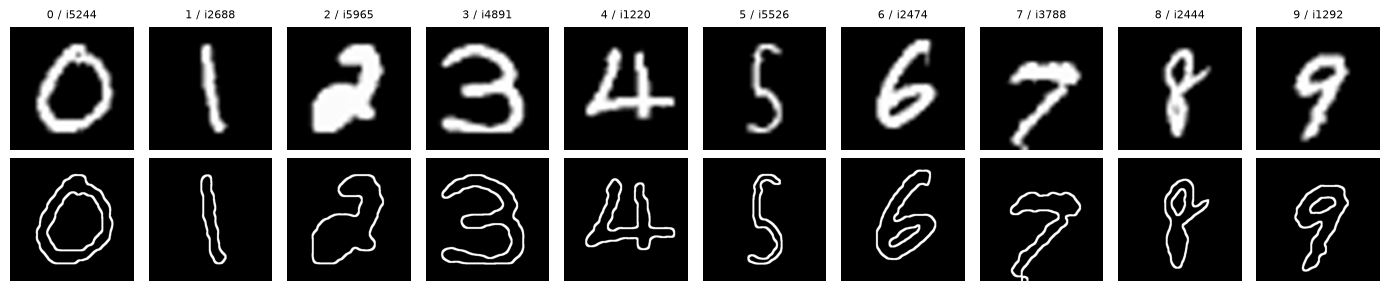

{'n_controls': 200, 'resolution': 512, 'edge_fraction_mean': 0.0062, 'edge_fraction_min': 0.003}
пример записи: {'control_id': 'c0_00_i5244', 'source_split': 'train', 'source_index': 5244, 'label': 0, 'gen_seed': 4205244, 'control_png': 'data/lab14/controls/ctrl_c0_00_i5244.png', 'source_png': 'data/lab14/sources/src_c0_00_i5244.png', 'control_sha1': '371c7afc17f3336b3c0a6f8db9a03e0bd87bbfdb', 'edge_fraction': 0.007457733154296875}
сохранено: artifacts\lab14\controls.jsonl | data\lab14\controls


In [3]:
# Задание 2. Контуры Canny и происхождение меток
# Каждый контур строится из одной реальной train-сцены (задание 1); её индекс, класс и
# фиксированный seed генерации записываются рядом с PNG, чтобы synthetic получил ту же метку.
import cv2
from PIL import Image

CANNY_LOW, CANNY_HIGH = 100, 200   # пороги на увеличенном изображении 0..255
BLUR_KSIZE = 5                     # сглаживание пикселизации 28 -> RESOLUTION перед Canny
BINARIZE_AT = 127                  # после увеличения перепад яркости растянут на ~18 px и слабее порогов Canny,
                                   # поэтому форма цифры сначала бинаризуется — граница снова резкая
SOURCE_DIR = DATA_ROOT / 'sources' # увеличенные исходные цифры — для аудита и сравнения
SOURCE_DIR.mkdir(parents=True, exist_ok=True)
for old in list(CONTROL_DIR.glob('ctrl_*.png')) + list(SOURCE_DIR.glob('src_*.png')):
    old.unlink()  # не оставлять файлы от прогона с другим PER_CLASS/RESOLUTION

def canny_control(img28):
    up = cv2.resize(img28, (RESOLUTION, RESOLUTION), interpolation=cv2.INTER_CUBIC)
    up = cv2.GaussianBlur(up, (BLUR_KSIZE, BLUR_KSIZE), 0)
    _, mask = cv2.threshold(up, BINARIZE_AT, 255, cv2.THRESH_BINARY)
    edges = cv2.Canny(mask, CANNY_LOW, CANNY_HIGH)
    return up, edges

def file_sha1(path):
    return hashlib.sha1(Path(path).read_bytes()).hexdigest()

CONTROLS = []
for c in range(N_CLASSES):
    for k, idx in enumerate(CONTROL_INDICES[c]):
        control_id = f'c{c}_{k:02d}_i{idx}'
        up, edges = canny_control(train_x[idx])
        ctrl_path = CONTROL_DIR / f'ctrl_{control_id}.png'
        src_path = SOURCE_DIR / f'src_{control_id}.png'
        # ControlNet ожидает 3-канальное условие: белые контуры на чёрном фоне
        Image.fromarray(np.stack([edges] * 3, axis=-1)).save(ctrl_path)
        Image.fromarray(up).save(src_path)
        CONTROLS.append({
            'control_id': control_id, 'source_split': 'train', 'source_index': int(idx),
            'label': int(train_y[idx]), 'gen_seed': SEED * 100_000 + int(idx),
            'control_png': ctrl_path.as_posix(), 'source_png': src_path.as_posix(),
            'control_sha1': file_sha1(ctrl_path),
            'edge_fraction': float((edges > 0).mean()),
        })

# Проверка происхождения: перечитываем PNG с диска и сверяем с исходной сценой
for row in CONTROLS:
    reread = np.array(Image.open(row['control_png']).convert('L'))
    _, expected = canny_control(train_x[row['source_index']])
    assert reread.shape == (RESOLUTION, RESOLUTION)
    assert np.array_equal(reread, expected), f"контур не воспроизводится: {row['control_id']}"
    assert row['label'] == int(train_y[row['source_index']]), 'метка не из исходной сцены'
    assert row['edge_fraction'] > 0, f"пустой контур: {row['control_id']}"
assert len({r['gen_seed'] for r in CONTROLS}) == len(CONTROLS), 'seeds должны быть уникальны'

with open(ARTIFACTS / 'controls.jsonl', 'w', encoding='utf-8') as f:
    for row in CONTROLS:
        f.write(json.dumps(row, ensure_ascii=False) + '\n')

edge_fr = np.array([r['edge_fraction'] for r in CONTROLS])
save_json('controls_summary.json', {
    'n_controls': len(CONTROLS), 'resolution': RESOLUTION,
    'canny': {'low': CANNY_LOW, 'high': CANNY_HIGH, 'blur_ksize': BLUR_KSIZE,
              'binarize_at': BINARIZE_AT, 'upscale': 'INTER_CUBIC'},
    'seed_rule': 'gen_seed = SEED * 100000 + source_index',
    'per_class': {str(c): sum(r['label'] == c for r in CONTROLS) for c in range(N_CLASSES)},
    'edge_fraction': {'mean': float(edge_fr.mean()), 'min': float(edge_fr.min()), 'max': float(edge_fr.max())},
    'checks': {'png_reproducible': True, 'labels_from_source_scene': True,
               'non_empty_edges': True, 'unique_seeds': True},
})

# Превью: по одному примеру на класс — исходная цифра и её контур
import matplotlib.pyplot as plt
PREVIEW_THICKEN = max(3, RESOLUTION // 64)   # 8 px при 512
first = {r['label']: r for r in reversed(CONTROLS)}
fig, axes = plt.subplots(2, N_CLASSES, figsize=(N_CLASSES * 1.4, 3))
for c in range(N_CLASSES):
    axes[0, c].imshow(Image.open(first[c]['source_png']), cmap='gray')
    # Только для отображения: линия в 1 px при уменьшении превью сливается с фоном, поэтому утолщаем;
    # PNG на диске и вход ControlNet не меняются
    ctrl = np.array(Image.open(first[c]['control_png']).convert('L'))
    axes[1, c].imshow(cv2.dilate(ctrl, np.ones((PREVIEW_THICKEN, PREVIEW_THICKEN), np.uint8)), cmap='gray')
    axes[0, c].set_title(f"{c} / i{first[c]['source_index']}", fontsize=8)
    for ax in axes[:, c]: ax.axis('off')
plt.tight_layout(); plt.savefig(ARTIFACTS / 'controls_preview.png', dpi=120); plt.show()

print({'n_controls': len(CONTROLS), 'resolution': RESOLUTION,
       'edge_fraction_mean': round(float(edge_fr.mean()), 4),
       'edge_fraction_min': round(float(edge_fr.min()), 4)})
print('пример записи:', CONTROLS[0])
print('сохранено:', ARTIFACTS / 'controls.jsonl', '|', CONTROL_DIR)

### Задание 3. Загрузка предобученного ControlNet

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима.

**Результат.** Проверяемое состояние «Загрузка предобученного ControlNet» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите SD1.5 и Canny ControlNet с совместимым scheduler; CPU-имитация недопустима» и его результат доступен следующему этапу.

**Задание 3. Загрузка предобученного ControlNet**

- **Что делали**: загрузили SD1.5 и `lllyasviel/sd-controlnet-canny` в fp16, поставили UniPC из конфига SD1.5, запустили на GPU без offload; сделали общую функцию `generate`.
- **Зачем**: один генератор с одинаковыми размером, шагами и seed-правилом для всех следующих заданий; CPU-имитация запрещена.
- **Результат**: `model_info.json`, `load_check.png`; RTX 3060 (12 ГБ), загрузка 10 с, пробная генерация 5.1 с (512 px, 20 шагов), пик видеопамяти 3.33 ГБ. Контур повторён точно, но вместо цифры получился предмет-«брелок».

Подготавливаем ControlNet - понимает контуры Canny и SD1.5 - генератор изображений.

W1109 21:54:53.387000 19092 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
Unable to import `torchao` Tensor objects. This may affect loading checkpoints serialized with `torchao`
c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\huggingface_hub\utils\_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(
c:\Users\bogom\OneDrive\Документы\PSY\6 курс\МО\.venv\Lib\site-packages\diffusers\utils\deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

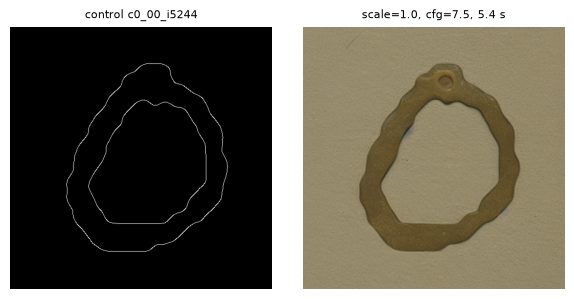

{'dtype': 'torch.float16', 'device': 'NVIDIA GeForce RTX 3060', 'execution_device': 'cuda:0', 'sequential_offload': False, 'resolution': 512, 'num_inference_steps': 20, 'load_seconds': 17.0, 'peak_vram_gb': 3.33}
scheduler: UniPCMultistepScheduler
revisions: 451f4fe16113bff5a5d2269ed5ad43b0592e9a14 | 7f2f69197050967007f6bbd23ab5e52f0384162a
контрольная генерация: {'control_id': 'c0_00_i5244', 'seed': 4205244, 'seconds': 5.38, 'pixel_std': 28.08, 'image': 'artifacts/lab14/load_check.png'}
versions: {'python': '3.12.1', 'torch': '2.11.0+cu128', 'cuda': '12.8', 'diffusers': '0.41.0', 'transformers': '5.17.0', 'accelerate': '1.15.0', 'opencv': '5.0.0'}


In [4]:
# Задание 3. Загрузка предобученного ControlNet
# SD1.5 (заморожена) + готовый Canny ControlNet, FP16 inference на CUDA. Scheduler UniPC —
# рекомендованный в документации diffusers для ControlNet, создаётся из конфига самого SD1.5.
import platform, diffusers, transformers, accelerate
from diffusers import StableDiffusionControlNetPipeline, ControlNetModel, UniPCMultistepScheduler

if not torch.cuda.is_available():
    raise RuntimeError('Нужна CUDA: CPU-имитация генерации недопустима по условию работы.')

SD_MODEL_ID = os.getenv('CV_SD_MODEL', 'stable-diffusion-v1-5/stable-diffusion-v1-5')
CONTROLNET_ID = os.getenv('CV_CONTROLNET', 'lllyasviel/sd-controlnet-canny')
NUM_STEPS = 4 if FAST_DEV_RUN else 20   # шагов UniPC на одну генерацию

def hub_revision(repo_id):
    # commit sha загруженной версии — для воспроизводимости; офлайн вернёт None
    try:
        from huggingface_hub import HfApi
        return HfApi().model_info(repo_id).sha
    except Exception as e:
        return f'unknown ({type(e).__name__})'

torch.cuda.reset_peak_memory_stats()
t0 = time.time()
controlnet = ControlNetModel.from_pretrained(CONTROLNET_ID, torch_dtype=DTYPE)
pipe = StableDiffusionControlNetPipeline.from_pretrained(
    SD_MODEL_ID, controlnet=controlnet, torch_dtype=DTYPE,
    safety_checker=None, requires_safety_checker=False,  # цифры MNIST; ложные срабатывания дают чёрные кадры
)
pipe.scheduler = UniPCMultistepScheduler.from_config(pipe.scheduler.config)
if SEQUENTIAL_OFFLOAD:
    pipe.enable_sequential_cpu_offload()   # сокращённый режим: веса подгружаются на GPU по слоям
else:
    pipe.to('cuda')
pipe.set_progress_bar_config(disable=True)
load_seconds = time.time() - t0

def generate(control_png, prompt, seed, control_scale, cfg, negative_prompt=None, steps=None):
    # Единая точка генерации для всех следующих заданий: одинаковые размер, шаги и seed-правило.
    # CPU-генератор шума даёт одинаковый стартовый latent и с offload, и без него.
    control = Image.open(control_png).convert('RGB')
    generator = torch.Generator('cpu').manual_seed(int(seed))
    return pipe(prompt, image=control, negative_prompt=negative_prompt,
                num_inference_steps=steps or NUM_STEPS, guidance_scale=cfg,
                controlnet_conditioning_scale=control_scale,
                height=RESOLUTION, width=RESOLUTION, generator=generator).images[0]

# Проверка: модель реально считает на GPU и в FP16
assert pipe._execution_device.type == 'cuda', pipe._execution_device
assert pipe.unet.dtype == DTYPE and pipe.controlnet.dtype == DTYPE
assert isinstance(pipe.scheduler, UniPCMultistepScheduler)

# Контрольная генерация на первом контуре: время и пиковая память
check = CONTROLS[0]
torch.cuda.synchronize(); t1 = time.time()
check_img = generate(check['control_png'], f"a photo of the handwritten digit {check['label']}",
                     check['gen_seed'], control_scale=1.0, cfg=7.5)
torch.cuda.synchronize(); check_seconds = time.time() - t1
check_img.save(ARTIFACTS / 'load_check.png')
check_arr = np.asarray(check_img)
assert check_arr.shape == (RESOLUTION, RESOLUTION, 3) and check_arr.std() > 1, 'пустое/константное изображение'

model_info = {
    'sd_model': {'id': SD_MODEL_ID, 'revision': hub_revision(SD_MODEL_ID), 'license': 'CreativeML OpenRAIL-M'},
    'controlnet': {'id': CONTROLNET_ID, 'revision': hub_revision(CONTROLNET_ID), 'license': 'OpenRAIL'},
    'scheduler': {'class': type(pipe.scheduler).__name__, 'config': dict(pipe.scheduler.config)},
    'dtype': str(DTYPE), 'device': torch.cuda.get_device_name(0), 'vram_gb': round(VRAM_GB, 1),
    'execution_device': str(pipe._execution_device), 'sequential_offload': SEQUENTIAL_OFFLOAD,
    'resolution': RESOLUTION, 'num_inference_steps': NUM_STEPS, 'safety_checker': None,
    'load_seconds': round(load_seconds, 1),
    'check_generation': {'control_id': check['control_id'], 'seed': check['gen_seed'],
                         'seconds': round(check_seconds, 2), 'pixel_std': round(float(check_arr.std()), 2),
                         'image': (ARTIFACTS / 'load_check.png').as_posix()},
    'peak_vram_gb': round(torch.cuda.max_memory_allocated() / 2**30, 2),
    'versions': {'python': platform.python_version(), 'torch': torch.__version__, 'cuda': torch.version.cuda,
                 'diffusers': diffusers.__version__, 'transformers': transformers.__version__,
                 'accelerate': accelerate.__version__, 'opencv': cv2.__version__},
}
save_json('model_info.json', model_info)

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(Image.open(check['control_png'])); axes[0].set_title(f"control {check['control_id']}", fontsize=8)
axes[1].imshow(check_img); axes[1].set_title(f"scale=1.0, cfg=7.5, {check_seconds:.1f} s", fontsize=8)
for ax in axes: ax.axis('off')
plt.tight_layout(); plt.show()

print({k: model_info[k] for k in ('dtype', 'device', 'execution_device', 'sequential_offload',
                                 'resolution', 'num_inference_steps', 'load_seconds', 'peak_vram_gb')})
print('scheduler:', model_info['scheduler']['class'])
print('revisions:', model_info['sd_model']['revision'], '|', model_info['controlnet']['revision'])
print('контрольная генерация:', model_info['check_generation'])
print('versions:', model_info['versions'])

#### Как ControlNet и UNet работают вместе на одном шаге генерации

```text
шаг t:
  latent_t + текст + контур     -->  ControlNet   -->  поправки
  latent_t + текст + поправки   -->  UNet         -->  предсказанный шум
  latent_t - предсказанный шум  -->  scheduler    -->  latent_(t-1)

повторить NUM_STEPS раз (t = T ... 1), затем:
  latent_0                      -->  VAE-декодер  -->  итоговое изображение
```

- **latent_t** — текущее «полуготовое» изображение в сжатом виде (64×64×4 для 512 px); на первом шаге — чистый шум, полностью заданный seed.
- **текст** — эмбеддинги промпта из текстового энкодера CLIP (77×768), UNet и ControlNet читают их через cross-attention.
- **контур** — PNG Canny из задания 2; его видит только ControlNet.
- **поправки** — признаки ControlNet, прибавляемые к активациям замороженного UNet; их сила умножается на `controlnet_conditioning_scale` (0 — обычный SD1.5, 1 — стандартное следование контуру).
- **scheduler** (UniPC) вычитает предсказанный шум; после последнего шага VAE-декодер переводит latent в картинку `RESOLUTION × RESOLUTION`.

Весь цикл выполняется внутри вызова `pipe(...)` в функции `generate`.

```text
промпт ──► CLIP text encoder ──► эмбеддинги текста ─┐
                                                     ▼
seed ──► шум (latent 64×64×4) ──► UNet × 20 шагов ──► чистый latent ──► VAE-декодер ──► картинка 512×512
                                    ▲
                    ControlNet (контур) ┘
```

Изображение генерируется вычитанием предсказанного шума из снега на каждойм из 20 шагов. Текст помогает сети предсказывать шум, потому что UNet обучали на зашумленных картинках по тексту понять какой шум добавили к оригиналу.<br>
Чистый latent это 64×64 точки по 4 числа в каждой. Каждая точка описывает участок 8×8 пикселей итогового изображения: его цвет, яркость, текстуру, край. VAE-декодер переводит latent обратно в пиксели.

Промпт при генерации
```text
a photo of the handwritten digit 0
```

Scale задаёт силу контура, CFG — силу текста.

**scale (`controlnet_conditioning_scale`) — насколько сильно модель обязана следовать контуру.** Это множитель на поправки, которые ControlNet добавляет в UNet:

```text
признаки UNet + scale × поправки ControlNet
```

- **0** — контур не влияет, это обычный SD1.5 (настройка `base`);
- **0.5** — контур учитывается, но модель может от него отходить;
- **1.0** — стандартная сила, как при обучении ControlNet. На пробной картинке видно, что форма повторена почти точно;
- **больше 1** — контур навязывается жёстче, появляются артефакты.

**CFG (`guidance_scale`) — насколько сильно модель следует промпту.** На каждом шаге UNet считается дважды, с промптом и без, и разница усиливается:

```text
шум = шум_без_текста + CFG × (шум_с_текстом − шум_без_текста)
```

- **1** — текст почти не усилен, картинка размытая и случайная;
- **3.5** — мягкое следование тексту;
- **7.5** — стандарт для SD1.5 (на пробной картинке);
- **9 и выше** — жёсткое следование тексту, выше контраст, меньше разнообразия.


### Задание 4. Факторная сетка генераций

*Вес: 1 балл.*

**Постановка.** Совместное изменение силы контроля и CFG выявляет компромисс между структурой контура и текстовым условием. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds.

**Результат.** Проверяемое состояние «Факторная сетка генераций» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сравните baseline и все сочетания силы контроля и CFG на одинаковых входах и seeds» и его результат доступен следующему этапу.

**Задание 4. Факторная сетка генераций**

- **Что делали**: для каждого из 200 контуров сделали 5 генераций — `base` (scale 0, CFG 7.5) и сетку scale {0.5, 1.0} × CFG {3.5, 9.0}; промпт и seed у всех настроек контура одинаковые.
- **Зачем**: увидеть компромисс «контур ↔ текст» на одинаковых входах.
- **Результат**: 1000 PNG, `synthetic.jsonl`, `grid_manifest.csv`, `grid_summary.json`, `grid_preview.png`; 3.66 с на изображение во всех настройках (≈ 12.2 мин на настройку, 61 мин всего); почти пустых картинок — 2 из 1000 (`s1.0_cfg3.5`).

Промпт
```text
a white handwritten digit {label} written with chalk on a black background, centered
```

Негативный промпт - то чего не должно быть
```text
text, letters, watermark, several digits, frame, colorful

```

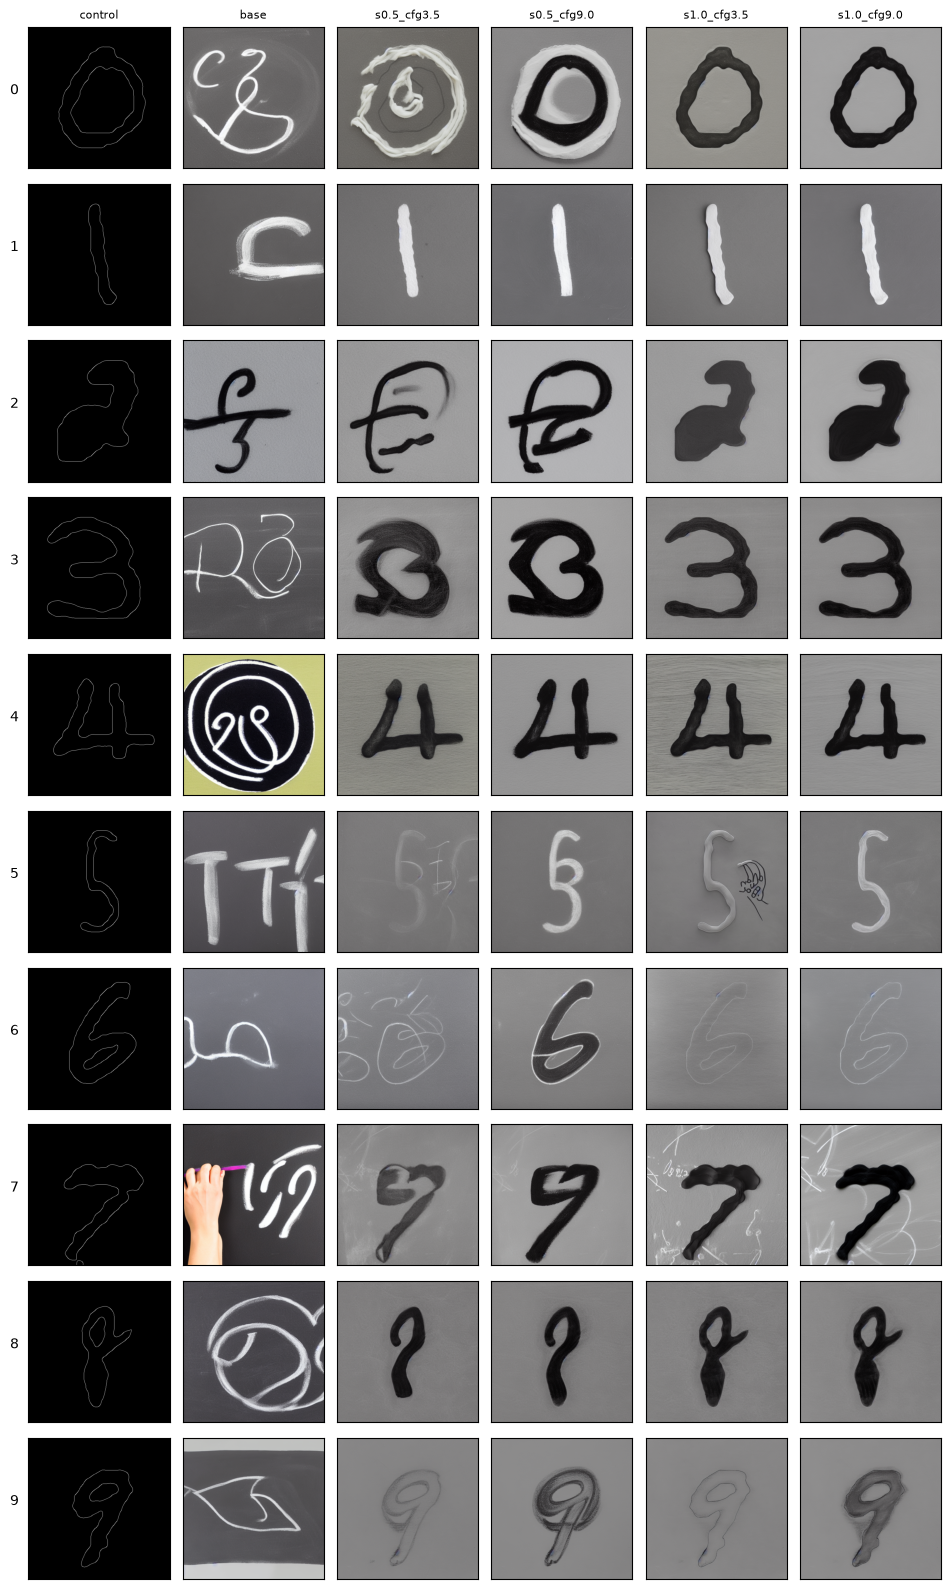

{'n_images': 1000, 'generated_this_run': 0, 'resolution': 512, 'steps': 20, 'grid_wall_seconds': 6.3}
             control_scale  cfg    n  sec_mean  sec_total  pixel_std_mean  near_blank
setting                                                                              
base                   0.0  7.5  200     3.664    732.875          47.148           0
s0.5_cfg3.5            0.5  3.5  200     3.661    732.149          29.013           0
s0.5_cfg9.0            0.5  9.0  200     3.659    731.848          40.220           0
s1.0_cfg3.5            1.0  3.5  200     3.658    731.679          23.916           2
s1.0_cfg9.0            1.0  9.0  200     3.660    732.013          30.903           0
сохранено: artifacts\lab14\synthetic.jsonl | artifacts\lab14\grid_manifest.csv | data\lab14\synthetic\r512_steps20


In [5]:
# Задание 4. Факторная сетка генераций
# Протокол: 5 генераций на контур = baseline + сетка 2x2 (control scale x CFG).
# Baseline — SD1.5 без контроля (scale=0): показывает, что именно добавляет ControlNet.
# Все настройки получают одни и те же контур, промпт и seed контура (задание 2).
import pandas as pd

PROMPT = 'a white handwritten digit {label} written with chalk on a black background, centered'
NEGATIVE_PROMPT = 'text, letters, watermark, several digits, frame, colorful'
BASELINE = {'setting': 'base', 'control_scale': 0.0, 'cfg': 7.5}
CONTROL_SCALES = [0.5, 1.0]
CFG_SCALES = [3.5, 9.0]
SETTINGS = [BASELINE] + [{'setting': f's{s}_cfg{g}', 'control_scale': s, 'cfg': g}
                         for s in CONTROL_SCALES for g in CFG_SCALES]

# Подкаталог по разрешению и шагам: smoke-прогон не смешивается с полным
RUN_DIR = SYNTH_DIR / f'r{RESOLUTION}_steps{NUM_STEPS}'
MANIFEST = ARTIFACTS / 'synthetic.jsonl'

def read_jsonl(path):
    if not Path(path).exists():
        return []
    return [json.loads(line) for line in Path(path).read_text(encoding='utf-8').splitlines() if line.strip()]

# Возобновление: уже сгенерированные картинки с тем же контуром/настройкой/режимом не пересчитываются
done = {(r['control_id'], r['setting'], r['resolution'], r['steps']): r
        for r in read_jsonl(MANIFEST) if Path(r['image_png']).exists()}

total = len(CONTROLS) * len(SETTINGS)
new_count, t_grid = 0, time.time()
with open(MANIFEST, 'a', encoding='utf-8') as manifest:
    for row in CONTROLS:
        prompt = PROMPT.format(label=row['label'])
        for st in SETTINGS:
            key = (row['control_id'], st['setting'], RESOLUTION, NUM_STEPS)
            if key in done:
                continue
            out_path = RUN_DIR / st['setting'] / f"{row['control_id']}.png"
            out_path.parent.mkdir(parents=True, exist_ok=True)
            torch.cuda.synchronize(); t0 = time.time()
            img = generate(row['control_png'], prompt, row['gen_seed'], st['control_scale'], st['cfg'],
                           negative_prompt=NEGATIVE_PROMPT)
            torch.cuda.synchronize(); seconds = time.time() - t0
            img.save(out_path)
            rec = {'control_id': row['control_id'], 'source_index': row['source_index'], 'label': row['label'],
                   'setting': st['setting'], 'control_scale': st['control_scale'], 'cfg': st['cfg'],
                   'seed': row['gen_seed'], 'prompt': prompt, 'negative_prompt': NEGATIVE_PROMPT,
                   'control_png': row['control_png'], 'image_png': out_path.as_posix(),
                   'resolution': RESOLUTION, 'steps': NUM_STEPS, 'seconds': round(seconds, 3),
                   'pixel_std': round(float(np.asarray(img).std()), 2)}
            manifest.write(json.dumps(rec, ensure_ascii=False) + '\n'); manifest.flush()
            done[key] = rec
            new_count += 1
            if new_count % 50 == 0:
                print(f'{len(done)}/{total} готово, {time.time() - t_grid:.0f} s')

# Таблица текущего прогона: только текущие контуры, настройки и режим
current_ids = {r['control_id'] for r in CONTROLS}
setting_names = [st['setting'] for st in SETTINGS]
GRID = pd.DataFrame([r for (cid, s, res, steps), r in done.items()
                     if cid in current_ids and res == RESOLUTION and steps == NUM_STEPS and s in setting_names])
GRID.to_csv(ARTIFACTS / 'grid_manifest.csv', index=False)

# Проверки факторного дизайна: полная сетка, одинаковые входы и seeds во всех настройках
assert len(GRID) == total, f'сетка неполная: {len(GRID)} из {total}'
per_control = GRID.groupby('control_id').agg(n=('setting', 'nunique'), seeds=('seed', 'nunique'),
                                             prompts=('prompt', 'nunique'), controls=('control_png', 'nunique'))
assert (per_control['n'] == len(SETTINGS)).all(), 'у контура не все настройки'
assert (per_control[['seeds', 'prompts', 'controls']] == 1).all().all(), 'входы или seeds различаются между настройками'
assert (GRID['label'] == GRID['source_index'].map(lambda i: int(train_y[i]))).all(), 'метка не из исходной сцены'

timing = (GRID.groupby('setting')
              .agg(control_scale=('control_scale', 'first'), cfg=('cfg', 'first'), n=('image_png', 'size'),
                   sec_mean=('seconds', 'mean'), sec_total=('seconds', 'sum'),
                   pixel_std_mean=('pixel_std', 'mean'), near_blank=('pixel_std', lambda s: int((s < 5).sum())))
              .reindex(setting_names).round(3))
save_json('grid_summary.json', {
    'prompt_template': PROMPT, 'negative_prompt': NEGATIVE_PROMPT, 'settings': SETTINGS,
    'resolution': RESOLUTION, 'steps': NUM_STEPS, 'scheduler': type(pipe.scheduler).__name__,
    'n_controls': len(CONTROLS), 'n_images': len(GRID), 'generated_this_run': new_count,
    'seed_rule': 'одинаковый gen_seed контура во всех настройках',
    'checks': {'complete_grid': True, 'same_seed_prompt_control_per_contour': True, 'labels_from_source_scene': True},
    'per_setting': timing.reset_index().to_dict(orient='records'),
})

# Превью: по одному контуру на класс; столбцы — контур и все настройки на одном seed
show = GRID.drop_duplicates('label').sort_values('label')['control_id'].tolist()
fig, axes = plt.subplots(len(show), len(SETTINGS) + 1, figsize=(1.6 * (len(SETTINGS) + 1), 1.6 * len(show)))
axes = np.atleast_2d(axes)
for r, cid in enumerate(show):
    sub = GRID[GRID['control_id'] == cid].set_index('setting')
    axes[r, 0].imshow(Image.open(sub['control_png'].iloc[0]))
    axes[r, 0].set_ylabel(str(sub['label'].iloc[0]), rotation=0, labelpad=10)
    for c, name in enumerate(setting_names, start=1):
        axes[r, c].imshow(Image.open(sub.loc[name, 'image_png']))
    for ax in axes[r]:
        ax.set_xticks([]); ax.set_yticks([])
for c, title in enumerate(['control'] + setting_names):
    axes[0, c].set_title(title, fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'grid_preview.png', dpi=110); plt.show()

print({'n_images': len(GRID), 'generated_this_run': new_count, 'resolution': RESOLUTION, 'steps': NUM_STEPS,
       'grid_wall_seconds': round(time.time() - t_grid, 1)})
print(timing.to_string())
print('сохранено:', MANIFEST, '|', ARTIFACTS / 'grid_manifest.csv', '|', RUN_DIR)

#### Параметры сетки: control scale и CFG

**Control scale** (`controlnet_conditioning_scale`) — сила контура: множитель на поправки ControlNet, прибавляемые к признакам UNet.

`признаки UNet + control_scale × поправки ControlNet`

| scale | что происходит |
|---|---|
| 0.0 | поправки обнулены — чистый SD1.5, контур не влияет (наш `base`) |
| 0.5 | поправки вдвое слабее — модель учитывает контур, но может от него отступать |
| 1.0 | стандартная сила, с которой ControlNet обучали |
| > 1 | контур навязывается жёстче, часто появляются артефакты |

**CFG** (`guidance_scale`, classifier-free guidance) — сила текста. На каждом шаге UNet считается с промптом и с негативным (пустым) промптом, итоговый шум:

`шум = шум_без_текста + CFG × (шум_с_текстом − шум_без_текста)`

| CFG | что происходит |
|---|---|
| 1 | текст учитывается «как есть», без усиления — картинка часто размытая и случайная |
| 3.5 | мягкое следование тексту — естественнее и разнообразнее |
| 7.5 | стандартное значение для SD1.5 |
| 9 и выше | жёсткое следование тексту — растут насыщенность и контраст, падает разнообразие |

«Слабый» и «сильный» в сетке — это значения параметров относительно стандартных (scale 1.0, CFG 7.5), а не измерения. Фактическое следование контуру и тексту проверяется в задании 5: edge F1 и CLIP text-image cosine.

### Задание 5. Структурное и текстовое соответствие

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine.

**Результат.** Проверяемое состояние «Структурное и текстовое соответствие» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Из реальных PNG рассчитайте edge F1 с допуском и CLIP text-image cosine» и его результат доступен следующему этапу.

**Задание 5. Структурное и текстовое соответствие**

- **Что делали**: по PNG с диска посчитали edge F1 с допуском 4 px (края генерации против контура), CLIP ViT-B/32 cos к промпту и zero-shot цифру по CLIP.
- **Зачем**: отдельно измерить геометрию и соответствие тексту — один CLIP score ничего не говорит о форме и классе.
- **Результат**: `metrics_per_image.csv`, `metrics_summary.json`, `structure_vs_text.png`; Edge F1: base 0.09, scale 0.5 — 0.35 / 0.45, scale 1.0 — 0.74 / 0.87 (CFG 3.5 / 9.0); CLIP cos 0.276–0.316, максимум у base; CLIP угадывает цифру лишь в 11.5–31 % генераций и в 33.5 % реальных MNIST.

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

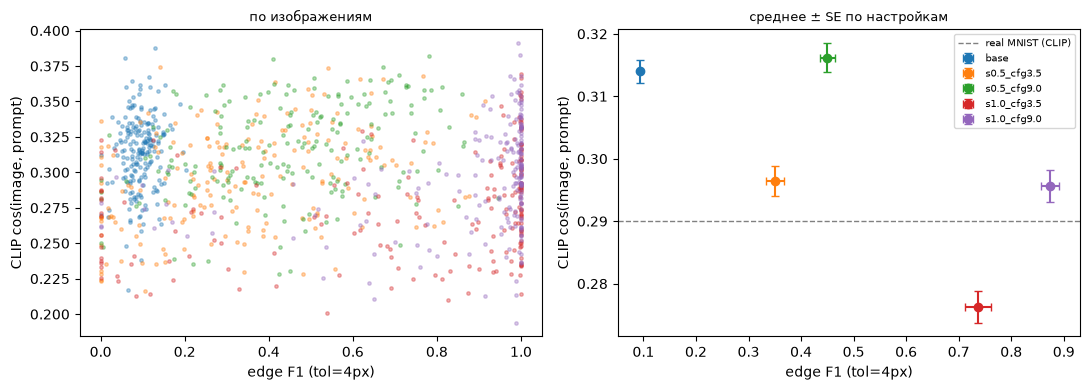

параметр,значение
изображений,1000
"допуск edge F1, px",4
модель CLIP,openai/clip-vit-base-patch32
"real MNIST: CLIP cos(image, prompt)",0.29
real MNIST: CLIP zero-shot accuracy,0.335


настройка,scale,CFG,n,Edge P,Edge R,Edge F1,F1 ±SE,CLIP cos,CLIP ±SE,CLIP digit acc
base,0.000,7.500,200,0.077,0.141,0.093,0.002,0.314,0.002,0.115
s0.5_cfg3.5,0.500,3.500,200,0.395,0.387,0.351,0.016,0.296,0.002,0.205
s0.5_cfg9.0,0.500,9.000,200,0.420,0.546,0.450,0.015,0.316,0.002,0.285
s1.0_cfg3.5,1.000,3.500,200,0.877,0.708,0.737,0.025,0.276,0.002,0.225
s1.0_cfg9.0,1.000,9.000,200,0.941,0.868,0.874,0.017,0.296,0.003,0.310


цифра,base,s0.5_cfg3.5,s0.5_cfg9.0,s1.0_cfg3.5,s1.0_cfg9.0
0,0.118,0.435,0.506,0.645,0.926
1,0.075,0.410,0.509,0.804,0.858
2,0.104,0.263,0.366,0.722,0.883
3,0.099,0.337,0.449,0.683,0.868
4,0.093,0.360,0.464,0.809,0.895
5,0.105,0.282,0.350,0.703,0.865
6,0.077,0.365,0.427,0.805,0.883
7,0.088,0.309,0.408,0.728,0.831
8,0.085,0.425,0.534,0.635,0.790
9,0.088,0.320,0.486,0.837,0.941


цифра,base,s0.5_cfg3.5,s0.5_cfg9.0,s1.0_cfg3.5,s1.0_cfg9.0
0,0.323,0.287,0.309,0.256,0.270
1,0.319,0.280,0.307,0.259,0.272
2,0.322,0.287,0.299,0.274,0.292
3,0.316,0.302,0.320,0.301,0.314
4,0.310,0.301,0.326,0.274,0.308
5,0.309,0.300,0.313,0.288,0.302
6,0.320,0.303,0.325,0.276,0.295
7,0.308,0.308,0.330,0.276,0.308
8,0.304,0.303,0.326,0.275,0.294
9,0.311,0.293,0.307,0.283,0.303


сохранено: artifacts\lab14\metrics_per_image.csv | artifacts\lab14\metrics_summary.json


In [6]:
# Задание 5. Структурное и текстовое соответствие
# Все метрики считаются по сохранённым PNG с диска, а не по объектам в памяти.
# Edge F1 — геометрия: совпадают ли края генерации с входным контуром (с допуском в пикселях).
# CLIP cosine — текст: похожа ли картинка на промпт. Ни одна из них не доказывает класс цифры,
# поэтому дополнительно записывается zero-shot предсказание цифры по CLIP — как отдельный диагностический столбец.
from scipy.ndimage import distance_transform_edt
from transformers import CLIPModel, CLIPProcessor

EDGE_TOL = max(2, round(RESOLUTION / 128))   # допуск: 4 px при 512, 2 px при 256
GEN_CANNY = (100, 200)                       # те же пороги, что для контуров
# Для оценки — CLIP, отличный от текстового энкодера SD1.5 (ViT-L/14), чтобы не мерить модель её же энкодером
CLIP_ID = os.getenv('CV_CLIP_MODEL', 'openai/clip-vit-base-patch32')
CLIP_BATCH = 32

def edges_of_generated(path):
    gray = np.array(Image.open(path).convert('L'))
    gray = cv2.GaussianBlur(gray, (BLUR_KSIZE, BLUR_KSIZE), 0)
    return cv2.Canny(gray, *GEN_CANNY) > 0

def edge_f1(pred, target, tol=EDGE_TOL):
    # precision: доля найденных краёв в пределах tol от контура; recall: доля контура, покрытая краями генерации
    if pred.sum() == 0 or target.sum() == 0:
        return 0.0, 0.0, 0.0
    dist_to_target = distance_transform_edt(~target)
    dist_to_pred = distance_transform_edt(~pred)
    precision = float((dist_to_target[pred] <= tol).mean())
    recall = float((dist_to_pred[target] <= tol).mean())
    f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)
    return precision, recall, f1

# --- Edge F1 по всем генерациям ---
edge_rows = []
for r in GRID.itertuples():
    target = np.array(Image.open(r.control_png).convert('L')) > 0
    pred = edges_of_generated(r.image_png)
    p, rc, f1 = edge_f1(pred, target)
    edge_rows.append({'control_id': r.control_id, 'setting': r.setting, 'edge_precision': p,
                      'edge_recall': rc, 'edge_f1': f1, 'gen_edge_fraction': float(pred.mean())})
edge_df = pd.DataFrame(edge_rows)

# --- CLIP text-image cosine ---
clip_model = CLIPModel.from_pretrained(CLIP_ID, torch_dtype=torch.float16).to(DEVICE).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)

def as_features(out):
    # transformers 5 возвращает объект, где pooler_output — уже спроецированные признаки
    out = getattr(out, 'pooler_output', out)
    return torch.nn.functional.normalize(out.float(), dim=-1)

@torch.no_grad()
def clip_text_features(texts):
    batch = clip_proc(text=texts, return_tensors='pt', padding=True, truncation=True).to(DEVICE)
    return as_features(clip_model.get_text_features(**batch))

@torch.no_grad()
def clip_image_features(paths):
    feats = []
    for i in range(0, len(paths), CLIP_BATCH):
        imgs = [Image.open(p).convert('RGB') for p in paths[i:i + CLIP_BATCH]]
        batch = clip_proc(images=imgs, return_tensors='pt').to(DEVICE)
        feats.append(as_features(clip_model.get_image_features(pixel_values=batch['pixel_values'].half())))
    return torch.cat(feats)

img_feat = clip_image_features(GRID['image_png'].tolist())
prompts = sorted(GRID['prompt'].unique())
prompt_feat = dict(zip(prompts, clip_text_features(prompts)))
clip_prompt_cos = torch.stack([img_feat[i] @ prompt_feat[p] for i, p in enumerate(GRID['prompt'])]).cpu().numpy()

# Zero-shot цифра: только диагностика, не замена проверки класса downstream-классификатором
digit_texts = [f'a handwritten digit {d}' for d in range(N_CLASSES)]
digit_logits = (img_feat @ clip_text_features(digit_texts).T).cpu().numpy()

METRICS = GRID[['control_id', 'source_index', 'label', 'setting', 'control_scale', 'cfg', 'seed',
                'image_png', 'control_png', 'seconds', 'pixel_std']].merge(edge_df, on=['control_id', 'setting'])
METRICS['clip_prompt_cos'] = clip_prompt_cos
METRICS['clip_digit_cos'] = digit_logits[np.arange(len(GRID)), GRID['label'].to_numpy()]
METRICS['clip_digit_pred'] = digit_logits.argmax(1)
METRICS['clip_digit_correct'] = METRICS['clip_digit_pred'] == METRICS['label']
assert len(METRICS) == len(GRID) and METRICS[['edge_f1', 'clip_prompt_cos']].notna().all().all()

# Референс: те же метрики CLIP на реальных исходных цифрах (увеличенные PNG из задания 2)
real_paths = [r['source_png'] for r in CONTROLS]
real_feat = clip_image_features(real_paths)
real_labels = np.array([r['label'] for r in CONTROLS])
real_prompt_cos = np.array([float(real_feat[i] @ prompt_feat[PROMPT.format(label=l)]) for i, l in enumerate(real_labels)])
real_digit_logits = (real_feat @ clip_text_features(digit_texts).T).cpu().numpy()
real_ref = {'clip_prompt_cos_mean': float(real_prompt_cos.mean()),
            'clip_digit_acc': float((real_digit_logits.argmax(1) == real_labels).mean())}

METRICS.to_csv(ARTIFACTS / 'metrics_per_image.csv', index=False)

def mean_se(s):
    return f'{s.mean():.3f} ± {s.std(ddof=1) / np.sqrt(len(s)):.3f}' if len(s) > 1 else f'{s.mean():.3f}'

summary = (METRICS.groupby('setting')
                  .agg(control_scale=('control_scale', 'first'), cfg=('cfg', 'first'), n=('edge_f1', 'size'),
                       edge_precision=('edge_precision', 'mean'), edge_recall=('edge_recall', 'mean'),
                       edge_f1=('edge_f1', 'mean'), edge_f1_se=('edge_f1', lambda s: s.std(ddof=1) / np.sqrt(len(s))),
                       clip_prompt_cos=('clip_prompt_cos', 'mean'),
                       clip_prompt_cos_se=('clip_prompt_cos', lambda s: s.std(ddof=1) / np.sqrt(len(s))),
                       clip_digit_acc=('clip_digit_correct', 'mean'))
                  .reindex(setting_names).round(4))
f1_by_class = METRICS.pivot_table(index='label', columns='setting', values='edge_f1').reindex(columns=setting_names).round(3)
clip_by_class = METRICS.pivot_table(index='label', columns='setting', values='clip_prompt_cos').reindex(columns=setting_names).round(3)
f1_by_class.to_csv(ARTIFACTS / 'edge_f1_by_class.csv')
clip_by_class.to_csv(ARTIFACTS / 'clip_cos_by_class.csv')

save_json('metrics_summary.json', {
    'edge_f1': {'tolerance_px': EDGE_TOL, 'resolution': RESOLUTION, 'generated_canny': list(GEN_CANNY),
                'blur_ksize': BLUR_KSIZE, 'target': 'PNG-контур из задания 2'},
    'clip': {'model': CLIP_ID, 'text': 'промпт генерации', 'digit_texts': digit_texts},
    'real_reference': real_ref,
    'per_setting': summary.reset_index().to_dict(orient='records'),
    'per_setting_text': {s: {'edge_f1': mean_se(g['edge_f1']), 'clip_prompt_cos': mean_se(g['clip_prompt_cos'])}
                         for s, g in METRICS.groupby('setting')},
})

# Компромисс структура/текст: средние по настройкам и разброс по изображениям
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name in setting_names:
    g = METRICS[METRICS['setting'] == name]
    axes[0].scatter(g['edge_f1'], g['clip_prompt_cos'], s=6, alpha=0.35, label=name)
    axes[1].errorbar(g['edge_f1'].mean(), g['clip_prompt_cos'].mean(),
                     xerr=g['edge_f1'].std(ddof=1) / np.sqrt(len(g)),
                     yerr=g['clip_prompt_cos'].std(ddof=1) / np.sqrt(len(g)), fmt='o', capsize=3, label=name)
axes[1].axhline(real_ref['clip_prompt_cos_mean'], ls='--', c='gray', lw=1, label='real MNIST (CLIP)')
for ax, title in zip(axes, ['по изображениям', 'среднее ± SE по настройкам']):
    ax.set_xlabel(f'edge F1 (tol={EDGE_TOL}px)'); ax.set_ylabel('CLIP cos(image, prompt)'); ax.set_title(title, fontsize=9)
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'structure_vs_text.png', dpi=120); plt.show()

# Таблицы выводятся как HTML: границы ячеек, полосы строк, компактные заголовки без горизонтальной прокрутки
from IPython.display import display

TABLE_CSS = [
    {'selector': '', 'props': 'border-collapse: collapse; font-size: 12px; margin: 4px 0 14px 0;'},
    {'selector': 'caption', 'props': 'caption-side: top; text-align: left; font-weight: bold; padding: 4px 0;'},
    {'selector': 'th, td', 'props': 'border: 1px solid rgba(127,127,127,0.55); padding: 3px 8px; text-align: right;'},
    {'selector': 'th', 'props': 'background: rgba(127,127,127,0.22); white-space: normal; text-align: center;'},
    {'selector': 'tbody tr:nth-child(even)', 'props': 'background: rgba(127,127,127,0.09);'},
    {'selector': 'tbody tr:hover', 'props': 'background: rgba(66,133,244,0.18);'},
]

def show_table(df, caption, digits=3, bold_max=(), gradient=None):
    # bold_max — столбцы, где выделить лучшее значение; gradient=(vmin, vmax) — цветовая шкала по числам
    floats = df.select_dtypes('float').columns
    sty = (df.style.hide(axis='index').set_caption(caption).set_table_styles(TABLE_CSS)
             .format({c: f'{{:.{digits}f}}' for c in floats}))
    if bold_max:
        sty = sty.highlight_max(subset=list(bold_max), props='font-weight: bold; text-decoration: underline;')
    if gradient:
        num = df.select_dtypes('number').columns.drop(df.columns[0], errors='ignore')
        sty = sty.background_gradient(cmap='RdYlGn', vmin=gradient[0], vmax=gradient[1], subset=list(num))
    display(sty)

show_table(pd.DataFrame([
    ('изображений', len(METRICS)), ('допуск edge F1, px', EDGE_TOL), ('модель CLIP', CLIP_ID),
    ('real MNIST: CLIP cos(image, prompt)', round(real_ref['clip_prompt_cos_mean'], 4)),
    ('real MNIST: CLIP zero-shot accuracy', round(real_ref['clip_digit_acc'], 4)),
], columns=['параметр', 'значение']).astype({'значение': str}), 'Параметры оценки')

summary_view = summary.reset_index().rename(columns={
    'setting': 'настройка', 'control_scale': 'scale', 'cfg': 'CFG', 'edge_precision': 'Edge P',
    'edge_recall': 'Edge R', 'edge_f1': 'Edge F1', 'edge_f1_se': 'F1 ±SE', 'clip_prompt_cos': 'CLIP cos',
    'clip_prompt_cos_se': 'CLIP ±SE', 'clip_digit_acc': 'CLIP digit acc'})
show_table(summary_view, 'Средние по настройкам (n изображений на настройку)', digits=3,
           bold_max=('Edge P', 'Edge R', 'Edge F1', 'CLIP cos', 'CLIP digit acc'))

for table, title in ((f1_by_class, 'Edge F1 по классам'), (clip_by_class, 'CLIP cos(image, prompt) по классам')):
    view = table.rename_axis(columns=None).reset_index().rename(columns={'label': 'цифра'})
    lo, hi = (0, 1) if 'F1' in title else (float(table.min().min()), float(table.max().max()))
    show_table(view, title, gradient=(lo, hi))

print('сохранено:', ARTIFACTS / 'metrics_per_image.csv', '|', ARTIFACTS / 'metrics_summary.json')

#### Описание столбцов таблиц задания 5

**Таблица «Параметры оценки»** — условия, при которых посчитаны метрики.

| Параметр | Что значит |
|---|---|
| изображений | число оценённых генераций: контуры × настройки |
| допуск edge F1, px | `EDGE_TOL`: на сколько пикселей край генерации может отстоять от контура и всё ещё считаться совпавшим |
| модель CLIP | модель для оценки текста; отличается от текстового энкодера SD1.5, чтобы генератор не оценивался своим же энкодером |
| real MNIST: CLIP cos(image, prompt) | тот же CLIP cosine, посчитанный на **реальных** цифрах MNIST (увеличенные исходники контуров) с тем же промптом — ориентир «какой балл у настоящей цифры» |
| real MNIST: CLIP zero-shot accuracy | доля реальных цифр, которые CLIP узнаёт без обучения, выбирая из 10 текстов «a handwritten digit 0…9» — показывает, насколько CLIP вообще различает цифры |

**Таблица «Средние по настройкам»** — главная: каждая строка — одна настройка генерации (одна и та же модель SD1.5 + ControlNet, меняются только scale и CFG), значения усреднены по всем контурам этой настройки.

| Столбец | Что значит | Лучше |
|---|---|---|
| настройка | имя настройки: `base` — без контроля; `s<scale>_cfg<CFG>` — точка сетки | — |
| scale | `controlnet_conditioning_scale`, сила контура (0 — ControlNet выключен) | — |
| CFG | `guidance_scale`, сила текста | — |
| n | число изображений в настройке (контуров); все настройки получили одни и те же контуры и seeds | — |
| Edge P | edge precision: доля краёв генерации, лежащих не дальше допуска от контура; низкая — на картинке много лишних краёв (текстура, фон) | выше |
| Edge R | edge recall: доля контура, воспроизведённая краями генерации; низкая — части цифры потеряны | выше |
| Edge F1 | среднее гармоническое P и R — итоговое **структурное** соответствие контуру | выше |
| F1 ±SE | стандартная ошибка среднего Edge F1 (std / √n): если разница двух настроек меньше ~2 SE, она может быть шумом выборки | меньше |
| CLIP cos | косинусная близость эмбеддингов картинки и её промпта в CLIP — **текстовое** соответствие; сравнивать только между настройками, абсолютное значение у CLIP обычно в диапазоне ~0.2–0.35 | выше |
| CLIP ±SE | стандартная ошибка среднего CLIP cos | меньше |
| CLIP digit acc | доля генераций, где CLIP zero-shot выбрал верную цифру из 10 вариантов; грубая диагностика класса, не доказательство — сравнивать с real MNIST accuracy из первой таблицы. Генерируется  10 текстов кандидатов и их вектора сравниваются с ветором сгенерированной картинки | выше |

Жирным с подчёркиванием выделено лучшее значение в каждом метрическом столбце. Компромисс «структура ↔ текст» читается по паре столбцов **Edge F1** и **CLIP cos**: настройка, лучшая по одному, не обязана быть лучшей по другому.

**Таблицы «Edge F1 по классам» и «CLIP cos по классам»** — те же метрики, разбитые по цифрам.

| Элемент | Что значит |
|---|---|
| цифра | класс исходной MNIST-цифры, из которой построен контур (метка synthetic-изображения) |
| столбцы `base`, `s…_cfg…` | среднее значение метрики для этой цифры при этой настройке (по контурам этой цифры) |
| цвет ячейки | шкала от красного (хуже) к зелёному (лучше); для Edge F1 — от 0 до 1, для CLIP — от минимума до максимума таблицы |

По этим таблицам видно, какие цифры хуже держат контур или хуже соответствуют тексту при одной и той же настройке — кандидаты для аудита худших случаев в задании 7.

#### Edge F1 с допуском: precision, recall, F1

Метрика отвечает на вопрос: **совпадают ли края сгенерированной картинки с входным контуром?**

1. **Цель (target)** — PNG-контур Canny из задания 2, который получал ControlNet.
2. **Предсказание (pred)** — края сгенерированной картинки: тот же Canny (размытие 5×5, пороги 100/200) по PNG генерации с диска.
3. Пиксели краёв сравниваются **с допуском** `EDGE_TOL` (4 px при 512, 2 px при 256): край считается совпавшим, если ближайший край другой карты лежит не дальше допуска. Расстояния считаются через distance transform.

| Метрика | Формула | Что значит | Когда низкая |
|---|---|---|---|
| **Precision** | доля краёв генерации, лежащих ≤ tol от контура | «всё ли, что нарисовано, — по контуру?» | лишние края: текстура, фон, посторонние объекты |
| **Recall** | доля пикселей контура, у которых есть край генерации ≤ tol | «весь ли контур воспроизведён?» | части цифры потеряны или размыты |
| **F1** | 2 · P · R / (P + R) | баланс обоих; высокий, только если высоки оба | любая из двух проблем |

**Зачем допуск.** Генерация повторяет форму, но край может сместиться на 1–3 пикселя (сглаживание, толщина линии, VAE). Без допуска почти идеальная картинка получила бы низкий F1 из-за попиксельного сдвига. Допуск в несколько пикселей при 512 px — это меньше 1% ширины изображения.

**Пограничные случаи.** Если у генерации нет ни одного края, F1 = 0. Высокий F1 подтверждает только геометрию: он не говорит, похожа ли картинка на цифру и на текст промпта — для этого CLIP cosine и downstream-классификатор.

### Задание 6. Разнообразие внутри класса

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Измерьте попарные различия изображений внутри одного класса и настройки.

**Результат.** Проверяемое состояние «Разнообразие внутри класса» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Измерьте попарные различия изображений внутри одного класса и настройки» и его результат доступен следующему этапу.

**Задание 6. Разнообразие внутри класса**

- **Что делали**: внутри каждой пары (цифра, настройка) сравнили все 190 пар картинок по pixel L1 (64×64) и CLIP dist; то же для 20 реальных цифр каждого класса.
- **Зачем**: проверить, не штампует ли модель одинаковые картинки, и сравнить с разнообразием настоящих данных.
- **Результат**: `diversity_pairs.csv`, `diversity_summary.json`, `diversity.png`; 11 400 пар; pixel L1 при scale 1.0 — 0.81–0.99 от real (0.141), CLIP dist в 4.6–5.8 раза выше real (0.037): форма как у MNIST, стиль намного разнообразнее.

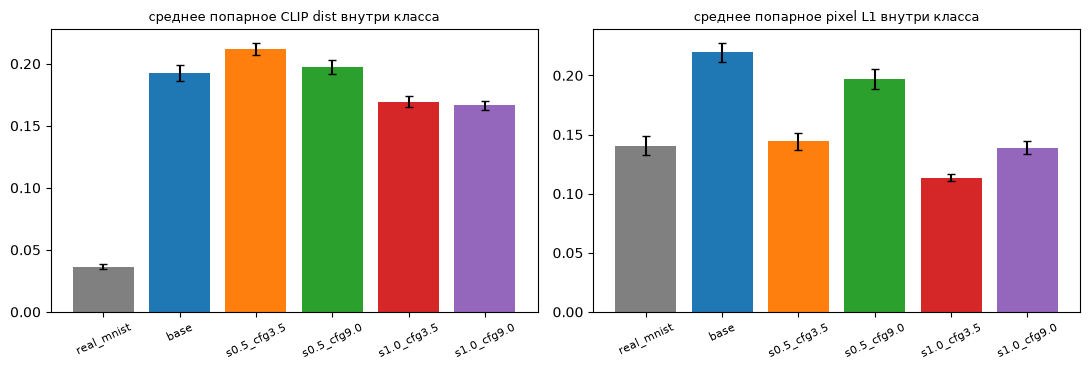

параметр,значение
пар всего,11400
"пар на группу (класс, настройка)",190
pixel L1,"|a−b| по пикселям, 64×64, оттенки серого"
CLIP dist,1 − cos эмбеддингов openai/clip-vit-base-patch32


настройка,scale,CFG,классов,пар,pixel L1,L1 ±SE,CLIP dist,CLIP ±SE,CLIP dist min,L1 / real,CLIP / real
real_mnist,—,—,10,1900,0.141,0.008,0.037,0.002,0.006,1.000,1.000
base,0.000000,7.500000,10,1900,0.220,0.008,0.192,0.007,0.024,1.561,5.261
s0.5_cfg3.5,0.500000,3.500000,10,1900,0.144,0.007,0.212,0.005,0.055,1.025,5.797
s0.5_cfg9.0,0.500000,9.000000,10,1900,0.197,0.009,0.197,0.005,0.040,1.399,5.396
s1.0_cfg3.5,1.000000,3.500000,10,1900,0.113,0.003,0.169,0.005,0.053,0.806,4.635
s1.0_cfg9.0,1.000000,9.000000,10,1900,0.139,0.005,0.167,0.004,0.047,0.987,4.555


цифра,real_mnist,base,s0.5_cfg3.5,s0.5_cfg9.0,s1.0_cfg3.5,s1.0_cfg9.0
0,0.032,0.160,0.192,0.176,0.174,0.182
1,0.034,0.192,0.237,0.204,0.184,0.178
2,0.042,0.181,0.221,0.215,0.165,0.172
3,0.033,0.173,0.189,0.178,0.166,0.162
4,0.045,0.177,0.221,0.201,0.147,0.163
5,0.031,0.192,0.214,0.210,0.182,0.170
6,0.030,0.208,0.216,0.196,0.168,0.159
7,0.048,0.224,0.228,0.210,0.194,0.174
8,0.035,0.223,0.202,0.169,0.160,0.144
9,0.035,0.194,0.202,0.213,0.154,0.159


цифра,real_mnist,base,s0.5_cfg3.5,s0.5_cfg9.0,s1.0_cfg3.5,s1.0_cfg9.0
0,0.167,0.197,0.131,0.189,0.123,0.167
1,0.081,0.194,0.120,0.154,0.112,0.136
2,0.165,0.200,0.151,0.219,0.112,0.139
3,0.147,0.218,0.171,0.223,0.122,0.146
4,0.147,0.209,0.130,0.187,0.116,0.158
5,0.149,0.243,0.156,0.213,0.124,0.148
6,0.144,0.253,0.181,0.235,0.115,0.135
7,0.120,0.259,0.159,0.211,0.107,0.123
8,0.149,0.231,0.132,0.181,0.093,0.109
9,0.138,0.192,0.111,0.158,0.110,0.129


сохранено: artifacts\lab14\diversity_pairs.csv | artifacts\lab14\diversity_by_class.csv | artifacts\lab14\diversity_summary.json


In [7]:
# Задание 6. Разнообразие внутри класса
# Для каждой пары (класс, настройка) берутся все её генерации (по одной на контур) и считаются
# попарные различия всех пар. Две меры дополняют друг друга:
#   pixel L1  — средняя |разность| яркостей (64x64, оттенки серого, 0..1): различие «на уровне пикселей»;
#   CLIP dist — 1 − cos между CLIP-эмбеддингами картинок (из задания 5): различие «по смыслу и стилю».
# Референс — те же меры на реальных цифрах MNIST, из которых построены контуры. Поскольку у каждой
# генерации свой контур, часть разнообразия унаследована от контуров; сравнение с real и base это показывает.
from itertools import combinations

DIV_SIZE = 64   # сторона уменьшенной копии для pixel L1

def gray_small(path):
    img = Image.open(path).convert('L').resize((DIV_SIZE, DIV_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.float32) / 255.0

# CLIP-эмбеддинги из задания 5, сопоставленные по пути файла (не по порядку строк)
feat_by_path = dict(zip(GRID['image_png'], img_feat.cpu().numpy()))
real_feat_np = real_feat.cpu().numpy()

def pairwise(items, group):
    # items: список (id, gray, clip_vec); возвращает строки по всем парам
    rows = []
    for (ia, ga, fa), (ib, gb, fb) in combinations(items, 2):
        rows.append({**group, 'id_a': ia, 'id_b': ib,
                     'pixel_l1': float(np.abs(ga - gb).mean()),
                     'clip_dist': float(1.0 - fa @ fb)})
    return rows

pair_rows = []
for (setting, label), g in METRICS.groupby(['setting', 'label']):
    items = [(r.control_id, gray_small(r.image_png), feat_by_path[r.image_png]) for r in g.itertuples()]
    pair_rows += pairwise(items, {'source': 'synthetic', 'setting': setting, 'label': int(label)})

# Реальные цифры: те же 20 исходных сцен на класс (увеличенные PNG из задания 2)
for label in range(N_CLASSES):
    items = [(r['control_id'], gray_small(r['source_png']), real_feat_np[i])
             for i, r in enumerate(CONTROLS) if r['label'] == label]
    pair_rows += pairwise(items, {'source': 'real', 'setting': 'real_mnist', 'label': label})

PAIRS = pd.DataFrame(pair_rows)
PAIRS.to_csv(ARTIFACTS / 'diversity_pairs.csv', index=False)

# Проверка: в каждой группе ровно C(n, 2) пар, без пар изображения с самим собой
n_per_group = METRICS.groupby(['setting', 'label']).size()
expected = int((n_per_group * (n_per_group - 1) // 2).sum()) + N_CLASSES * PER_CLASS * (PER_CLASS - 1) // 2
assert len(PAIRS) == expected, (len(PAIRS), expected)
assert (PAIRS['id_a'] != PAIRS['id_b']).all()

div_order = ['real_mnist'] + setting_names
group_stats = (PAIRS.groupby(['setting', 'label'])
                    .agg(pairs=('pixel_l1', 'size'), pixel_l1=('pixel_l1', 'mean'), pixel_l1_min=('pixel_l1', 'min'),
                         clip_dist=('clip_dist', 'mean'), clip_dist_min=('clip_dist', 'min'))
                    .reset_index())
group_stats.to_csv(ARTIFACTS / 'diversity_by_class.csv', index=False)

# По настройкам: среднее по классам и разброс между классами (SE по 10 классам)
def se(s):
    return s.std(ddof=1) / np.sqrt(len(s))

div_summary = (group_stats.groupby('setting')
                          .agg(classes=('label', 'nunique'), pairs=('pairs', 'sum'),
                               pixel_l1=('pixel_l1', 'mean'), pixel_l1_se=('pixel_l1', se),
                               clip_dist=('clip_dist', 'mean'), clip_dist_se=('clip_dist', se),
                               clip_dist_min=('clip_dist_min', 'min'))
                          .reindex(div_order).reset_index())
params = pd.DataFrame(SETTINGS).set_index('setting')
for pos, (col, src) in enumerate((('scale', 'control_scale'), ('CFG', 'cfg')), start=1):
    div_summary.insert(pos, col, div_summary['setting'].map(params[src]).astype(object).fillna('—'))
real_row = div_summary.set_index('setting').loc['real_mnist']
div_summary['l1_vs_real'] = div_summary['pixel_l1'] / real_row['pixel_l1']
div_summary['clip_vs_real'] = div_summary['clip_dist'] / real_row['clip_dist']

clip_div_by_class = group_stats.pivot_table(index='label', columns='setting', values='clip_dist').reindex(columns=div_order)
l1_div_by_class = group_stats.pivot_table(index='label', columns='setting', values='pixel_l1').reindex(columns=div_order)

save_json('diversity_summary.json', {
    'measures': {'pixel_l1': f'mean |a-b|, grayscale {DIV_SIZE}x{DIV_SIZE}, 0..1',
                 'clip_dist': f'1 - cos(CLIP image embeddings), {CLIP_ID}'},
    'groups': 'все пары изображений внутри (класс, настройка); real_mnist — исходные цифры тех же контуров',
    'n_pairs_total': len(PAIRS),
    'per_setting': div_summary.round(4).to_dict(orient='records'),
    'per_class_clip_dist': clip_div_by_class.round(4).reset_index().to_dict(orient='records'),
})

# Графики: разнообразие по настройкам и связь разнообразия с качеством контура
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
x = np.arange(len(div_order))
for ax, col, title in ((axes[0], 'clip_dist', 'CLIP dist'), (axes[1], 'pixel_l1', 'pixel L1')):
    ax.bar(x, div_summary[col], yerr=div_summary[f'{col}_se'], capsize=3,
           color=['gray'] + [f'C{i}' for i in range(len(setting_names))])
    ax.set_xticks(x, div_order, rotation=25, fontsize=8); ax.set_title(f'среднее попарное {title} внутри класса', fontsize=9)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'diversity.png', dpi=120); plt.show()

show_table(pd.DataFrame([
    ('пар всего', len(PAIRS)), ('пар на группу (класс, настройка)', PER_CLASS * (PER_CLASS - 1) // 2),
    ('pixel L1', f'|a−b| по пикселям, {DIV_SIZE}×{DIV_SIZE}, оттенки серого'),
    ('CLIP dist', f'1 − cos эмбеддингов {CLIP_ID}'),
], columns=['параметр', 'значение']).astype({'значение': str}), 'Параметры измерения разнообразия')

show_table(div_summary.rename(columns={
    'setting': 'настройка', 'classes': 'классов', 'pairs': 'пар', 'pixel_l1': 'pixel L1', 'pixel_l1_se': 'L1 ±SE',
    'clip_dist': 'CLIP dist', 'clip_dist_se': 'CLIP ±SE', 'clip_dist_min': 'CLIP dist min',
    'l1_vs_real': 'L1 / real', 'clip_vs_real': 'CLIP / real'}),
    'Разнообразие внутри класса по настройкам (среднее по 10 классам)', bold_max=('pixel L1', 'CLIP dist'))

for table, title in ((clip_div_by_class, 'CLIP dist внутри класса'), (l1_div_by_class, 'pixel L1 внутри класса')):
    view = table.rename_axis(columns=None).reset_index().rename(columns={'label': 'цифра'})
    show_table(view, title, gradient=(float(table.min().min()), float(table.max().max())))

print('сохранено:', ARTIFACTS / 'diversity_pairs.csv', '|', ARTIFACTS / 'diversity_by_class.csv', '|',
      ARTIFACTS / 'diversity_summary.json')

#### Попарный CLIP dist внутри класса

**CLIP dist** — мера разнообразия: насколько сгенерированные картинки **одной цифры при одной настройке** различаются между собой по смыслу и стилю. Маленькое значение — модель штампует похожие картинки.

**Алгоритм** (на примере группы «цифра 3, `s1.0_cfg9.0`» — 20 картинок по 20 разным контурам тройки):

1. Каждую картинку пропустить через CLIP → эмбеддинг из 512 чисел (взяты из задания 5).
2. Взять **все пары** картинок группы: 20·19/2 = **190** пар.
3. Для каждой пары посчитать `CLIP dist(a, b) = 1 − cos(E_a, E_b)`: 0 — CLIP считает картинки одинаковыми, больше — сильнее различаются.
4. Усреднить по 190 парам → одно число для группы.

То же для всех 10 цифр × 5 настроек и для `real_mnist` (реальные исходные цифры тех же контуров) — это ориентир «разнообразие настоящих данных».

```text
цифра 3, s1.0_cfg9.0:   img1  img2  img3  ...  img20
                        |--dist--|
                        |----dist----|
                        ... все 190 пар ...  -->  среднее = разнообразие группы
```

Сравнение идёт **внутри класса**: что тройка отличается от семёрки — ожидаемо и ничего не говорит; важно, разные ли *тройки* выдаёт модель.

**pixel L1 и CLIP dist**

| | pixel L1 | CLIP dist |
|---|---|---|
| формула | среднее \|a − b\| яркостей, 64×64, оттенки серого, 0..1 | 1 − cos(E_a, E_b) эмбеддингов CLIP |
| сравнивает | пиксели: форму, положение, фон | смысл и стиль: материал, текстуру, «что изображено» |
| две тройки разной формы в одном стиле «мел на доске» | **большая** — пиксели не совпадают | **маленькая** — для CLIP это одно и то же |
| две тройки одной формы: мелом и неоновая | маленькая или средняя | **большая** |
| что показывает в этой работе | разнообразие **формы** | разнообразие **стиля** (CLIP плохо различает сами цифры) |

### Задание 7. Аудит худших случаев

*Вес: 1 балл.*

**Постановка.** Не следует считать один CLIP score доказательством точной геометрии либо корректности класса цифры. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки.

**Результат.** Проверяемое состояние «Аудит худших случаев» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните построчные измерения и пять наихудших примеров, не приписывая им вымышленные оценки» и его результат доступен следующему этапу.

**Задание 7. Аудит худших случаев**

- **Что делали**: собрали построчную таблицу всех 1000 генераций со всеми измерениями и флагами по фиксированным порогам; выбрали 5 худших по Edge F1 среди 800 генераций со scale > 0.
- **Зачем**: найти типичные сбои по измерениям, без ручных оценок.
- **Результат**: `audit_rows.csv`, `worst_cases.json`, `worst_cases.png`, папка `worst_cases/`; у всех 5 худших F1 = 0, 4 из 5 — `s0.5_cfg3.5`, у 3 Canny не нашёл краёв вовсе (`no_edges`); флаг low_recall — у 67.5 % картинок `s0.5_cfg3.5` и у 12.5 % `s1.0_cfg9.0`.

В четвертом столбце зеленые пиксели это исходный контур, а красные это пиксели сгенерированного изображения. Их почти нет, потому что перепад по яркости недостаточный, цвета меняются плавно.

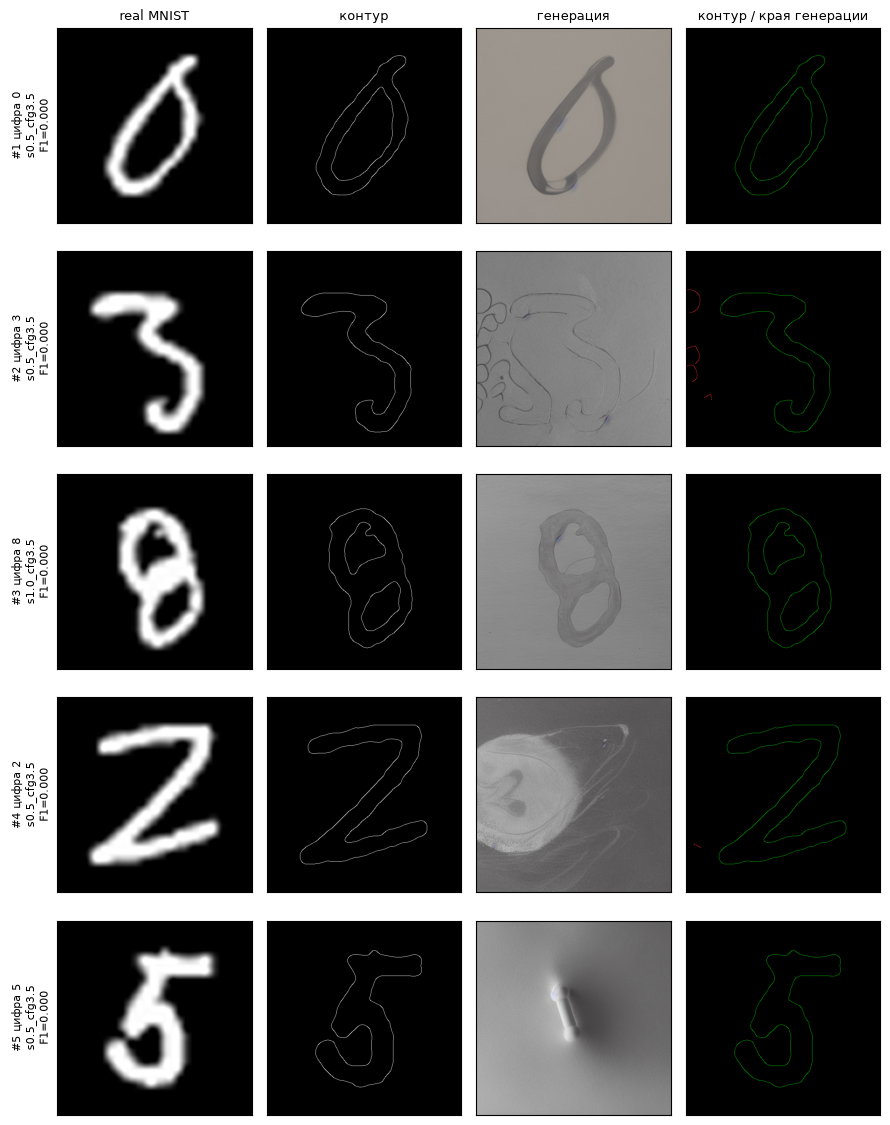

контур,индекс train,цифра,настройка,Edge P,Edge R,Edge F1,CLIP cos,CLIP цифра,CLIP NN dist,доля краёв,pixel std,флаги
c0_08_i30709,30709,0,s0.5_cfg3.5,0.000,0.000,0.000,0.224,0,0.139,0.000,13.030,"low_precision, low_recall, no_edges"
c3_07_i27856,27856,3,s0.5_cfg3.5,0.000,0.000,0.000,0.224,2,0.121,0.001,8.690,"low_precision, low_recall, clip_wrong_digit"
c8_08_i19460,19460,8,s1.0_cfg3.5,0.000,0.000,0.000,0.226,2,0.097,0.000,9.560,"low_precision, low_recall, clip_wrong_digit, no_edges"
c2_10_i40369,40369,2,s0.5_cfg3.5,0.000,0.000,0.000,0.228,2,0.178,0.000,28.660,"low_precision, low_recall"
c5_15_i46895,46895,5,s0.5_cfg3.5,0.000,0.000,0.000,0.230,2,0.188,0.000,28.810,"low_precision, low_recall, clip_wrong_digit, no_edges"


контур,индекс train,цифра,настройка,Edge P,Edge R,Edge F1,CLIP cos,CLIP цифра,CLIP NN dist,доля краёв,pixel std,флаги
c0_17_i50385,50385,0,s1.0_cfg9.0,0.999,0.977,0.988,0.194,2,0.149,0.008,28.460,clip_wrong_digit
c0_01_i5353,5353,0,s1.0_cfg3.5,0.891,0.385,0.538,0.201,2,0.131,0.004,22.190,"low_recall, clip_wrong_digit"
c0_06_i26308,26308,0,s1.0_cfg3.5,1.000,0.703,0.825,0.210,2,0.079,0.006,36.880,clip_wrong_digit
c3_08_i33223,33223,3,s1.0_cfg9.0,0.967,0.489,0.649,0.210,2,0.175,0.004,26.090,"low_recall, clip_wrong_digit"
c2_05_i23610,23610,2,s1.0_cfg9.0,0.841,1.000,0.913,0.213,2,0.127,0.007,47.610,


настройка,low_precision,low_recall,clip_wrong_digit,no_edges,near_blank,near_duplicate
base,1.000,1.000,0.885,0.000,0.000,0.030
s0.5_cfg3.5,0.660,0.675,0.795,0.030,0.000,0.000
s0.5_cfg9.0,0.640,0.390,0.715,0.020,0.000,0.030
s1.0_cfg3.5,0.100,0.285,0.775,0.070,0.010,0.000
s1.0_cfg9.0,0.025,0.125,0.690,0.015,0.000,0.010


флаг,правило,что значит
low_precision,edge_precision < 0.5,"больше половины краёв генерации — вне контура (текстура, фон)"
low_recall,edge_recall < 0.5,больше половины контура не воспроизведено
clip_wrong_digit,clip_digit_correct == False,CLIP zero-shot выбрал другую цифру
no_edges,gen_edge_fraction == 0,Canny не нашёл на генерации ни одного края (низкий контраст) — F1 = 0
near_blank,pixel_std < 5,почти однотонное изображение
near_duplicate,clip_nn_dist < 0.05,в той же группе есть почти такая же картинка по CLIP


{'rows': 1000, 'controlled': 800, 'worst_dir': 'artifacts/lab14/worst_cases'}
сохранено: artifacts\lab14\audit_rows.csv | artifacts\lab14\worst_cases.json | artifacts\lab14\worst_cases.png


In [8]:
# Задание 7. Аудит худших случаев
# Построчная таблица: все фактически измеренные значения для каждой из генераций (задания 4–6).
# «Худшие» выбираются по заранее заданному правилу, а не вручную; все пояснения — только флаги,
# вычисленные из этих же измерений по фиксированным порогам, без ручных или вымышленных оценок.
import shutil

N_WORST = 5
# Правило: среди генераций с включённым контролем (scale > 0) — наименьший edge F1, при равенстве — меньший CLIP cos.
# base не участвует: он по построению не обязан следовать контуру. Один контур — не больше одного раза в списке.
FLAG_RULES = {
    'low_precision': ('edge_precision', '<', 0.5, 'больше половины краёв генерации — вне контура (текстура, фон)'),
    'low_recall': ('edge_recall', '<', 0.5, 'больше половины контура не воспроизведено'),
    'clip_wrong_digit': ('clip_digit_correct', '==', False, 'CLIP zero-shot выбрал другую цифру'),
    'no_edges': ('gen_edge_fraction', '==', 0, 'Canny не нашёл на генерации ни одного края (низкий контраст) — F1 = 0'),
    'near_blank': ('pixel_std', '<', 5, 'почти однотонное изображение'),
    'near_duplicate': ('clip_nn_dist', '<', 0.05, 'в той же группе есть почти такая же картинка по CLIP'),
}

# Ближайший сосед внутри группы (класс, настройка) по CLIP dist — из пар задания 6
syn_pairs = PAIRS[PAIRS['source'] == 'synthetic']
nn = pd.concat([syn_pairs[['setting', 'id_a', 'clip_dist']].rename(columns={'id_a': 'control_id'}),
                syn_pairs[['setting', 'id_b', 'clip_dist']].rename(columns={'id_b': 'control_id'})])
nn = nn.groupby(['setting', 'control_id'])['clip_dist'].agg(clip_nn_dist='min', clip_mean_dist='mean').reset_index()

AUDIT = METRICS.merge(nn, on=['setting', 'control_id'], how='left')
AUDIT['edge_f1_rank_in_setting'] = AUDIT.groupby('setting')['edge_f1'].rank(method='first').astype(int)
ops = {'<': lambda s, v: s < v, '==': lambda s, v: s == v}
for name, (col, op, thr, _) in FLAG_RULES.items():
    AUDIT[f'flag_{name}'] = ops[op](AUDIT[col], thr)
flag_cols = [f'flag_{n}' for n in FLAG_RULES]
AUDIT['flags'] = AUDIT[flag_cols].apply(lambda r: ', '.join(c[5:] for c in flag_cols if r[c]), axis=1)
assert len(AUDIT) == len(METRICS) and AUDIT['clip_nn_dist'].notna().all()
AUDIT.to_csv(ARTIFACTS / 'audit_rows.csv', index=False)

controlled = AUDIT[AUDIT['control_scale'] > 0]
WORST = (controlled.sort_values(['edge_f1', 'clip_prompt_cos'])
                   .drop_duplicates('control_id').head(N_WORST).reset_index(drop=True))
WORST_CLIP = (controlled.sort_values(['clip_prompt_cos', 'edge_f1'])
                        .drop_duplicates('control_id').head(N_WORST).reset_index(drop=True))
assert len(WORST) == N_WORST

# Копии файлов худших примеров и наложение краёв: зелёный — входной контур, красный — края генерации
WORST_DIR = ARTIFACTS / 'worst_cases'
if WORST_DIR.exists():
    shutil.rmtree(WORST_DIR)
WORST_DIR.mkdir(parents=True)
source_by_id = {r['control_id']: r['source_png'] for r in CONTROLS}

def edge_overlay(row):
    target = np.array(Image.open(row.control_png).convert('L')) > 0
    pred = edges_of_generated(row.image_png)
    over = np.zeros((*target.shape, 3), dtype=np.uint8)
    over[target] = (0, 200, 0)
    over[pred] = (230, 40, 40)
    over[target & pred] = (255, 220, 0)   # совпадение пикселей в точности
    return over

fig, axes = plt.subplots(N_WORST, 4, figsize=(9, 2.3 * N_WORST))
for i, row in enumerate(WORST.itertuples()):
    tag = f'{i + 1}_{row.control_id}_{row.setting}'
    for src, suffix in ((row.image_png, 'gen'), (row.control_png, 'control'), (source_by_id[row.control_id], 'source')):
        shutil.copy(src, WORST_DIR / f'{tag}_{suffix}.png')
    over = edge_overlay(row)
    Image.fromarray(over).save(WORST_DIR / f'{tag}_overlay.png')
    panels = [Image.open(source_by_id[row.control_id]), Image.open(row.control_png), Image.open(row.image_png), over]
    for ax, img, title in zip(axes[i], panels, ['real MNIST', 'контур', 'генерация', 'контур / края генерации']):
        ax.imshow(img, cmap='gray' if title == 'real MNIST' else None); ax.set_xticks([]); ax.set_yticks([])
        if i == 0:
            ax.set_title(title, fontsize=9)
    axes[i, 0].set_ylabel(f'#{i + 1} цифра {row.label}\n{row.setting}\nF1={row.edge_f1:.3f}', fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'worst_cases.png', dpi=110); plt.show()

audit_cols = ['control_id', 'source_index', 'label', 'setting', 'seed', 'edge_precision', 'edge_recall', 'edge_f1',
              'clip_prompt_cos', 'clip_digit_pred', 'clip_nn_dist', 'gen_edge_fraction', 'pixel_std', 'flags']
save_json('worst_cases.json', {
    'rule': 'scale > 0; сортировка по edge_f1, затем clip_prompt_cos (по возрастанию); один контур не более одного раза',
    'flag_rules': {n: {'column': c, 'op': o, 'threshold': t, 'meaning': m} for n, (c, o, t, m) in FLAG_RULES.items()},
    'n_rows_audited': len(AUDIT), 'n_controlled': len(controlled),
    'worst_by_edge_f1': WORST[audit_cols + ['image_png', 'control_png']].to_dict(orient='records'),
    'worst_by_clip_cos': WORST_CLIP[audit_cols + ['image_png']].to_dict(orient='records'),
    'flag_counts_by_setting': AUDIT.groupby('setting')[flag_cols].sum().reindex(setting_names).to_dict(orient='index'),
    'files': {'rows': (ARTIFACTS / 'audit_rows.csv').as_posix(), 'images': WORST_DIR.as_posix(),
              'figure': (ARTIFACTS / 'worst_cases.png').as_posix()},
})

rename = {'control_id': 'контур', 'source_index': 'индекс train', 'label': 'цифра', 'setting': 'настройка',
          'edge_precision': 'Edge P', 'edge_recall': 'Edge R', 'edge_f1': 'Edge F1', 'clip_prompt_cos': 'CLIP cos',
          'clip_digit_pred': 'CLIP цифра', 'clip_nn_dist': 'CLIP NN dist', 'gen_edge_fraction': 'доля краёв', 'pixel_std': 'pixel std', 'flags': 'флаги'}
view_cols = [c for c in audit_cols if c != 'seed']
show_table(WORST[view_cols].rename(columns=rename), f'{N_WORST} наихудших по Edge F1 (scale > 0, разные контуры)')
show_table(WORST_CLIP[view_cols].rename(columns=rename), f'{N_WORST} наихудших по CLIP cos (scale > 0, разные контуры)')

flag_view = (AUDIT.groupby('setting')[flag_cols].mean().reindex(setting_names)
                  .rename(columns=lambda c: c[5:]).reset_index().rename(columns={'setting': 'настройка'}))
show_table(flag_view, 'Доля изображений с флагом по настройкам (из audit_rows.csv)', gradient=(0, 1))
show_table(pd.DataFrame([(n, f'{c} {o} {t}', m) for n, (c, o, t, m) in FLAG_RULES.items()],
                        columns=['флаг', 'правило', 'что значит']), 'Правила флагов (фиксированные пороги)')

print({'rows': len(AUDIT), 'controlled': len(controlled), 'worst_dir': WORST_DIR.as_posix()})
print('сохранено:', ARTIFACTS / 'audit_rows.csv', '|', ARTIFACTS / 'worst_cases.json', '|', ARTIFACTS / 'worst_cases.png')

#### Обозначения в таблицах задания 7

**Таблицы «5 наихудших по Edge F1» и «5 наихудших по CLIP cos»** — одна строка = одна генерация. Отбор: только scale > 0, сортировка по возрастанию метрики, каждый контур не более одного раза.

| Столбец | Что значит |
|---|---|
| контур | id контура: `c<цифра>_<номер>_i<индекс train>` |
| индекс train | индекс исходной цифры в MNIST train |
| цифра | метка: класс исходной цифры = метка synthetic-изображения |
| настройка | `s<scale>_cfg<CFG>` — точка сетки задания 4 |
| Edge P | доля краёв генерации рядом с контуром (мало — лишние края) |
| Edge R | доля контура, воспроизведённая генерацией (мало — контур потерян) |
| Edge F1 | баланс P и R — соответствие контуру |
| CLIP cos | близость картинки к промпту по CLIP |
| CLIP цифра | какую цифру выбрал CLIP zero-shot (сравнить с «цифра») |
| CLIP NN dist | CLIP dist до самой похожей картинки той же цифры и настройки (мало — почти дубликат) |
| доля краёв | доля пикселей генерации, где Canny нашёл край (0 — краёв нет, отсюда F1 = 0) |
| pixel std | разброс яркости пикселей (мало — картинка почти однотонная) |
| флаги | какие правила сработали (см. ниже) |

**Таблица «Доля изображений с флагом»** — строка = настройка, ячейка = доля её 200 генераций, у которых флаг сработал (0 — ни у одной, 1 — у всех).

**Флаги** — вычислены из измерений по фиксированным порогам, без ручных оценок:

| Флаг | Правило | Что значит |
|---|---|---|
| low_precision | Edge P < 0.5 | больше половины краёв — вне контура |
| low_recall | Edge R < 0.5 | больше половины контура не воспроизведено |
| clip_wrong_digit | CLIP цифра ≠ цифра | CLIP узнал другую цифру |
| no_edges | доля краёв = 0 | Canny не нашёл краёв (низкий контраст) |
| near_blank | pixel std < 5 | почти однотонное изображение |
| near_duplicate | CLIP NN dist < 0.05 | в группе есть почти такая же картинка |

**Рисунок `worst_cases.png`**: real MNIST → контур → генерация → наложение (зелёный — контур, красный — края генерации, жёлтый — точное совпадение).

### Задание 8. Архитектура downstream-классификатора

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Определите CNN и фиксированную реальную обучающую подвыборку.

**Результат.** Проверяемое состояние «Архитектура downstream-классификатора» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Определите CNN и фиксированную реальную обучающую подвыборку» и его результат доступен следующему этапу.

**Задание 8. Архитектура downstream-классификатора**

- **Что делали**: определили DigitCNN (2 свёрточных блока + классификатор) с общим init `cnn_init.pt`; обучающая подвыборка — 200 исходников контуров, валидация — 1000 других train-цифр, test — 10 000; синтетику привели к 28×28, светлая цифра на тёмном фоне.
- **Зачем**: «измерительный прибор», который покажет, полезна ли синтетика для распознавания цифр.
- **Результат**: `cnn_architecture.json`, `downstream_split.json`, `downstream_inputs.png`; 468 202 параметра, val accuracy до обучения 0.100; инвертировать пришлось 23.5 % генераций base и 65 % при scale 1.0.

C:\Users\bogom\AppData\Local\Temp\ipykernel_19092\2492156957.py:48: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  SYN_Y[name] = torch.from_numpy(g['label'].to_numpy()).long()


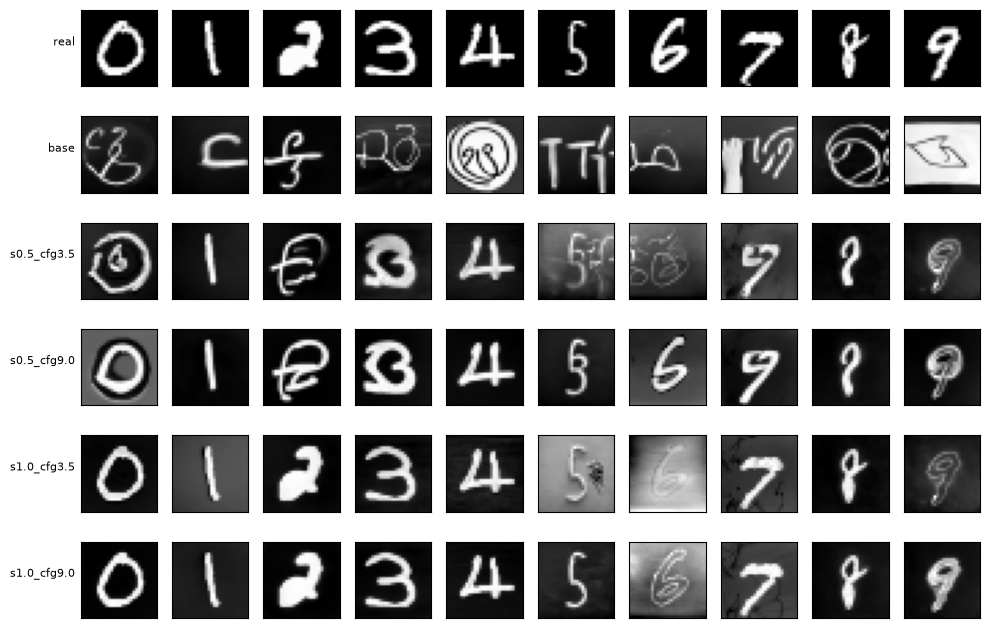

параметр,значение
реальная обучающая подвыборка,"200 (20 на класс, исходники контуров)"
"валидация (real train, вне подвыборки)",1000 (100 на класс)
test (real),10000
синтетика на настройку,200
параметров CNN,468 202
val accuracy до обучения,0.100
шагов оптимизатора на вариант,500
batch / optimizer / lr,64 / Adam / 0.001


слой,тип,параметров
features.0.0,Conv2d,320
features.0.1,BatchNorm2d,64
features.0.2,ReLU,0
features.0.3,Conv2d,9248
features.0.4,BatchNorm2d,64
features.0.5,ReLU,0
features.0.6,MaxPool2d,0
features.1.0,Conv2d,18496
features.1.1,BatchNorm2d,128
features.1.2,ReLU,0


настройка,n,доля инвертированных,средняя яркость,яркость real
base,200,0.235,0.282,0.132
s0.5_cfg3.5,200,0.495,0.322,0.132
s0.5_cfg9.0,200,0.500,0.258,0.132
s1.0_cfg3.5,200,0.650,0.337,0.132
s1.0_cfg9.0,200,0.650,0.270,0.132


сохранено: artifacts\lab14\cnn_architecture.json | artifacts\lab14\downstream_split.json | artifacts\lab14\cnn_init.pt


In [9]:
# Задание 8. Архитектура downstream-классификатора
# Режим малых данных: реальная обучающая подвыборка — те же 20 train-цифр на класс, из которых
# построены контуры (задание 1). Синтетика задания 4 — их «аугментация» с той же меткой, поэтому
# real+synthetic не получает новых реальных сцен: различие вариантов создаёт только синтетика.
# Валидация — отдельные реальные train-цифры (для контроля обучения, не test); test — независимый real test.
import torch.nn as nn

REAL_TRAIN_IDX = np.array(sorted(control_flat))       # фиксированная реальная подвыборка
VAL_PER_CLASS = 10 if FAST_DEV_RUN else 100
DOWNSTREAM = {'train_steps': 2 if FAST_DEV_RUN else 500, 'batch_size': 64, 'optimizer': 'Adam',
              'lr': 1e-3, 'weight_decay': 0.0, 'model_seed': SEED, 'batch_seed': SEED + 1}

# Валидация: реальные train-цифры, не входящие в обучающую подвыборку
val_rng = np.random.default_rng(SEED + 2)
used = set(REAL_TRAIN_IDX.tolist())
VAL_IDX = np.array(sorted(int(i) for c in range(N_CLASSES)
                          for i in val_rng.choice([j for j in np.flatnonzero(train_y == c) if j not in used],
                                                  size=VAL_PER_CLASS, replace=False)))
assert not set(VAL_IDX) & used, 'валидация пересекается с обучающей подвыборкой'
assert len(REAL_TRAIN_IDX) == N_CLASSES * PER_CLASS

def mnist_tensor(images):
    return torch.from_numpy(np.asarray(images, dtype=np.float32) / 255.0).unsqueeze(1)

REAL_TRAIN_X, REAL_TRAIN_Y = mnist_tensor(train_x[REAL_TRAIN_IDX]), torch.from_numpy(train_y[REAL_TRAIN_IDX]).long()
VAL_X, VAL_Y = mnist_tensor(train_x[VAL_IDX]), torch.from_numpy(train_y[VAL_IDX]).long()
TEST_IDX = np.array(TEST_INDICES)
TEST_X, TEST_Y = mnist_tensor(test_x[TEST_IDX]), torch.from_numpy(test_y[TEST_IDX]).long()

# Синтетика -> формат MNIST: оттенки серого, 28x28, светлая цифра на тёмном фоне, растяжение в 0..1.
# Полярность определяется по измерению: если рамка изображения светлее центра — картинка инвертируется.
def to_mnist(path):
    gray = np.asarray(Image.open(path).convert('L'), dtype=np.float32)
    small = cv2.resize(gray, (28, 28), interpolation=cv2.INTER_AREA)
    border = np.concatenate([small[:3].ravel(), small[-3:].ravel(), small[:, :3].ravel(), small[:, -3:].ravel()])
    inverted = bool(border.mean() > small[8:20, 8:20].mean())
    if inverted:
        small = 255.0 - small
    lo, hi = small.min(), small.max()
    small = (small - lo) / (hi - lo) if hi > lo else np.zeros_like(small)
    return small, inverted

SYN_X, SYN_Y, SYN_IDS, syn_prep = {}, {}, {}, []
for name in setting_names:
    g = GRID[GRID['setting'] == name].sort_values('control_id')
    arrs, flags = zip(*(to_mnist(p) for p in g['image_png']))
    SYN_X[name] = torch.from_numpy(np.stack(arrs)).unsqueeze(1)
    SYN_Y[name] = torch.from_numpy(g['label'].to_numpy()).long()
    SYN_IDS[name] = g['control_id'].tolist()
    syn_prep.append({'setting': name, 'n': len(g), 'inverted_share': float(np.mean(flags)),
                     'mean_intensity': float(SYN_X[name].mean()), 'real_mean_intensity': float(REAL_TRAIN_X.mean())})
    assert SYN_X[name].shape == (len(g), 1, 28, 28)
    assert (SYN_Y[name].numpy() == g['source_index'].map(lambda i: int(train_y[i])).to_numpy()).all()

class DigitCNN(nn.Module):
    # Небольшая CNN для 28x28: два свёрточных блока (по 2 свёртки + BN) и классификатор с dropout
    def __init__(self, n_classes=N_CLASSES):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                 nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(1, 32), block(32, 64))          # 28 -> 14 -> 7
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.3), nn.Linear(64 * 7 * 7, 128),
                                        nn.ReLU(inplace=True), nn.Dropout(0.3), nn.Linear(128, n_classes))

    def forward(self, x):
        return self.classifier(self.features(x))

def make_model():
    # Одинаковая инициализация для всех вариантов задания 9: веса берутся из сохранённого init-checkpoint
    model = DigitCNN().to(DEVICE)
    model.load_state_dict(torch.load(INIT_CKPT, map_location=DEVICE))
    return model

torch.manual_seed(DOWNSTREAM['model_seed'])
INIT_CKPT = ARTIFACTS / 'cnn_init.pt'
torch.save(DigitCNN().state_dict(), INIT_CKPT)

# Проверки архитектуры: форма выхода, число параметров, воспроизводимость инициализации
probe = make_model().eval()
with torch.no_grad():
    out = probe(REAL_TRAIN_X[:8].to(DEVICE))
    val_acc_init = float((probe(VAL_X.to(DEVICE)).argmax(1).cpu() == VAL_Y).float().mean())
assert out.shape == (8, N_CLASSES)
same_init = all(torch.equal(a, b) for a, b in zip(make_model().state_dict().values(), probe.state_dict().values()))
assert same_init, 'инициализация не воспроизводится'
n_params = sum(p.numel() for p in probe.parameters())
layers = [{'layer': name, 'type': type(m).__name__, 'params': sum(p.numel() for p in m.parameters(recurse=False))}
          for name, m in probe.named_modules() if len(list(m.children())) == 0]

save_json('downstream_split.json', {
    'real_train': {'rule': 'исходные train-сцены контуров (задание 1)', 'n': len(REAL_TRAIN_IDX),
                   'per_class': PER_CLASS, 'indices': REAL_TRAIN_IDX.tolist()},
    'val': {'rule': 'реальные train-цифры вне обучающей подвыборки', 'n': len(VAL_IDX),
            'per_class': VAL_PER_CLASS, 'seed': SEED + 2, 'indices': VAL_IDX.tolist()},
    'test': {'rule': 'официальный MNIST test (задание 1)', 'n': len(TEST_IDX)},
    'synthetic': {'per_setting': PER_CLASS * N_CLASSES, 'preprocessing': 'L -> 28x28 INTER_AREA -> инверсия, если рамка '
                  'светлее центра -> min-max в 0..1', 'stats': syn_prep},
    'checks': {'val_disjoint_from_train_subset': True, 'synthetic_labels_from_source_scene': True},
})
save_json('cnn_architecture.json', {
    'class': 'DigitCNN', 'input': '1x28x28, 0..1', 'n_params': n_params, 'layers': layers,
    'init_checkpoint': INIT_CKPT.as_posix(), 'training': DOWNSTREAM,
    'checks': {'output_shape': list(out.shape), 'same_init_reproducible': same_init,
               'val_acc_untrained': val_acc_init},
})

# Превью: реальные цифры и синтетика каждой настройки после приведения к формату MNIST (одни и те же контуры)
show_ids = GRID.drop_duplicates('label').sort_values('label')['control_id'].tolist()
fig, axes = plt.subplots(len(setting_names) + 1, N_CLASSES, figsize=(N_CLASSES * 1.0, 1.1 * (len(setting_names) + 1)))
for c, cid in enumerate(show_ids):
    src_idx = int(cid.split('_i')[-1])
    axes[0, c].imshow(train_x[src_idx], cmap='gray')
    for r, name in enumerate(setting_names, start=1):
        axes[r, c].imshow(SYN_X[name][SYN_IDS[name].index(cid), 0], cmap='gray')
for r, name in enumerate(['real'] + setting_names):
    axes[r, 0].set_ylabel(name, rotation=0, ha='right', fontsize=8)
for ax in axes.ravel():
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(ARTIFACTS / 'downstream_inputs.png', dpi=110); plt.show()

show_table(pd.DataFrame([
    ('реальная обучающая подвыборка', f'{len(REAL_TRAIN_IDX)} ({PER_CLASS} на класс, исходники контуров)'),
    ('валидация (real train, вне подвыборки)', f'{len(VAL_IDX)} ({VAL_PER_CLASS} на класс)'),
    ('test (real)', str(len(TEST_IDX))),
    ('синтетика на настройку', str(PER_CLASS * N_CLASSES)),
    ('параметров CNN', f'{n_params:,}'.replace(',', ' ')),
    ('val accuracy до обучения', f'{val_acc_init:.3f}'),
    ('шагов оптимизатора на вариант', str(DOWNSTREAM['train_steps'])),
    ('batch / optimizer / lr', f"{DOWNSTREAM['batch_size']} / {DOWNSTREAM['optimizer']} / {DOWNSTREAM['lr']}"),
], columns=['параметр', 'значение']), 'Downstream: данные и модель')
show_table(pd.DataFrame(layers).rename(columns={'layer': 'слой', 'type': 'тип', 'params': 'параметров'}),
           'Архитектура DigitCNN')
show_table(pd.DataFrame(syn_prep).rename(columns={'setting': 'настройка', 'inverted_share': 'доля инвертированных',
                                                  'mean_intensity': 'средняя яркость',
                                                  'real_mean_intensity': 'яркость real'}),
           'Синтетика после приведения к формату MNIST')
print('сохранено:', ARTIFACTS / 'cnn_architecture.json', '|', ARTIFACTS / 'downstream_split.json', '|', INIT_CKPT)

### Задание 9. Равнобюджетное обучение с аугментацией

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите real-only и real+synthetic варианты с одинаковым числом обновлений.

**Результат.** Проверяемое состояние «Равнобюджетное обучение с аугментацией» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите real-only и real+synthetic варианты с одинаковым числом обновлений» и его результат доступен следующему этапу.

**Задание 9. Равнобюджетное обучение с аугментацией**

- **Что делали**: обучили 6 вариантов — real_only и real + синтетика каждой из 5 настроек; у всех 500 шагов, batch 64, Adam 1e-3, одинаковые init и seeds.
- **Зачем**: разница в качестве должна объясняться только синтетикой, а не бюджетом или стартом.
- **Результат**: `checkpoints/`, `downstream_train.json`, `downstream_train_log.csv`, `downstream_curves.png`; у всех 32 000 примеров, доля синтетики в батчах 0.51; val acc: real_only 0.939, `s1.0_cfg9.0` 0.937, base 0.878; 2.6–3.4 с на вариант.

real_only          updates=500  val_acc=0.9390  3.0 s
real+base          updates=500  val_acc=0.8780  2.7 s
real+s0.5_cfg3.5   updates=500  val_acc=0.9200  2.7 s
real+s0.5_cfg9.0   updates=500  val_acc=0.9250  2.6 s
real+s1.0_cfg3.5   updates=500  val_acc=0.9260  2.6 s
real+s1.0_cfg9.0   updates=500  val_acc=0.9370  2.6 s


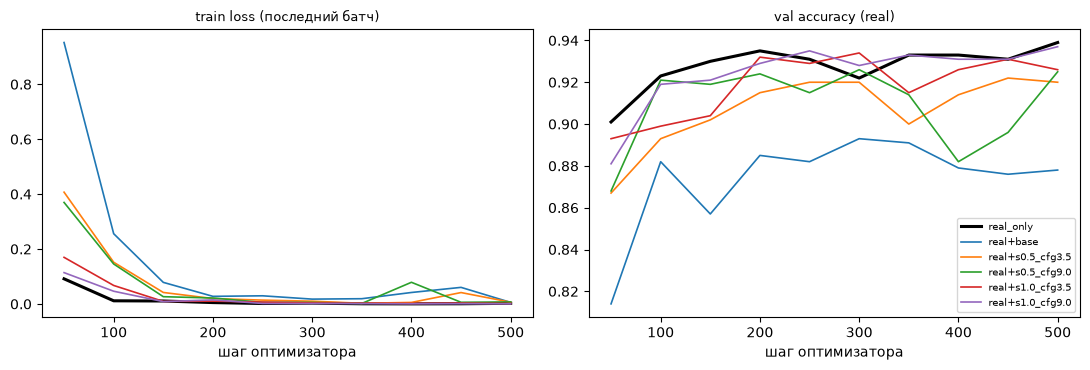

вариант,real,synthetic,шагов,примеров просмотрено,доля synthetic в батчах,train loss,acc на real train,val acc,val acc max,"время, с"
real_only,200,0,500,32000,0.000,0.002,1.000,0.939,0.939,2.980
real+base,200,200,500,32000,0.509,0.006,1.000,0.878,0.893,2.670
real+s0.5_cfg3.5,200,200,500,32000,0.509,0.006,1.000,0.920,0.922,2.670
real+s0.5_cfg9.0,200,200,500,32000,0.509,0.007,1.000,0.925,0.926,2.630
real+s1.0_cfg3.5,200,200,500,32000,0.509,0.002,1.000,0.926,0.934,2.580
real+s1.0_cfg9.0,200,200,500,32000,0.509,0.000,1.000,0.937,0.937,2.590


сохранено: artifacts\lab14\downstream_train.json | artifacts\lab14\downstream_train_log.csv | artifacts\lab14\checkpoints


In [10]:
# Задание 9. Равнобюджетное обучение с аугментацией
# Варианты: real_only и real+<настройка> для каждой из 5 настроек сетки (включая base без контроля).
# Равный бюджет: одинаковые стартовые веса (cnn_init.pt), число шагов оптимизатора, batch size, lr и
# расписание seed. Отличается только пул обучающих картинок: 200 real либо 200 real + 200 synthetic.
# Test здесь не используется; модель — веса после последнего шага, без выбора по валидации.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

VARIANTS = {'real_only': (REAL_TRAIN_X, REAL_TRAIN_Y)}
for name in setting_names:
    VARIANTS[f'real+{name}'] = (torch.cat([REAL_TRAIN_X, SYN_X[name]]), torch.cat([REAL_TRAIN_Y, SYN_Y[name]]))
EVAL_EVERY = 1 if FAST_DEV_RUN else 50
CKPT_DIR = ARTIFACTS / 'checkpoints'
CKPT_DIR.mkdir(parents=True, exist_ok=True)

@torch.no_grad()
def evaluate(model, x, y, batch=1000):
    model.eval()
    preds = torch.cat([model(x[i:i + batch].to(DEVICE)).argmax(1).cpu() for i in range(0, len(x), batch)])
    return float((preds == y).float().mean()), preds

def train_variant(name, x, y):
    torch.manual_seed(DOWNSTREAM['model_seed'])                     # одинаковый поток dropout
    batch_rng = np.random.default_rng(DOWNSTREAM['batch_seed'])     # одинаковое расписание выборки батчей
    model = make_model()
    init_ok = torch.equal(next(model.parameters()).detach().cpu(), next(probe.parameters()).detach().cpu())
    opt = torch.optim.Adam(model.parameters(), lr=DOWNSTREAM['lr'], weight_decay=DOWNSTREAM['weight_decay'])
    loss_fn = nn.CrossEntropyLoss()
    x_dev, y_dev = x.to(DEVICE), y.to(DEVICE)
    log, updates, seen_syn, t0 = [], 0, 0, time.time()
    for step in range(1, DOWNSTREAM['train_steps'] + 1):
        idx = batch_rng.integers(0, len(x), size=DOWNSTREAM['batch_size'])   # с возвращением: пул 200 < 500·64
        idx_t = torch.from_numpy(idx).to(DEVICE)
        model.train()
        loss = loss_fn(model(x_dev[idx_t]), y_dev[idx_t])
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
        updates += 1
        seen_syn += int((idx >= len(REAL_TRAIN_X)).sum())
        if step % EVAL_EVERY == 0 or step == DOWNSTREAM['train_steps']:
            val_acc, _ = evaluate(model, VAL_X, VAL_Y)
            log.append({'variant': name, 'step': step, 'train_loss': float(loss.item()), 'val_acc': val_acc})
    seconds = time.time() - t0
    ckpt = CKPT_DIR / f'cnn_{name}.pt'
    torch.save({'state_dict': model.state_dict(), 'variant': name, 'updates': updates,
                'downstream': DOWNSTREAM}, ckpt)
    train_acc, _ = evaluate(model, x, y)
    real_acc, _ = evaluate(model, REAL_TRAIN_X, REAL_TRAIN_Y)
    info = {'variant': name, 'n_train': len(x), 'n_real': len(REAL_TRAIN_X), 'n_synthetic': len(x) - len(REAL_TRAIN_X),
            'updates': updates, 'samples_seen': updates * DOWNSTREAM['batch_size'], 'synthetic_share_seen': seen_syn / (updates * DOWNSTREAM['batch_size']),
            'final_train_loss': log[-1]['train_loss'], 'train_acc': train_acc, 'real_train_acc': real_acc,
            'val_acc_final': log[-1]['val_acc'], 'val_acc_best': max(r['val_acc'] for r in log),
            'seconds': round(seconds, 2), 'same_init': init_ok, 'checkpoint': ckpt.as_posix()}
    return model, info, log

MODELS, TRAIN_INFO, TRAIN_LOG = {}, [], []
for name, (x, y) in VARIANTS.items():
    model, info, log = train_variant(name, x, y)
    MODELS[name] = model.eval()
    TRAIN_INFO.append(info); TRAIN_LOG += log
    print(f"{name:<18} updates={info['updates']}  val_acc={info['val_acc_final']:.4f}  {info['seconds']:.1f} s")

TRAIN_INFO = pd.DataFrame(TRAIN_INFO)
TRAIN_LOG = pd.DataFrame(TRAIN_LOG)
TRAIN_LOG.to_csv(ARTIFACTS / 'downstream_train_log.csv', index=False)

# Проверка равного бюджета: число обновлений, просмотренных примеров и стартовые веса совпадают у всех вариантов
assert TRAIN_INFO['updates'].nunique() == 1 and TRAIN_INFO['updates'].iloc[0] == DOWNSTREAM['train_steps']
assert TRAIN_INFO['samples_seen'].nunique() == 1 and TRAIN_INFO['same_init'].all()

save_json('downstream_train.json', {
    'budget': {**DOWNSTREAM, 'eval_every': EVAL_EVERY, 'sampling': 'равномерно с возвращением из пула варианта',
               'model_selection': 'веса после последнего шага; test не используется'},
    'variants': TRAIN_INFO.to_dict(orient='records'),
    'checks': {'equal_updates': True, 'equal_samples_seen': True, 'same_init': True},
})

# Кривые обучения на валидации (real train, вне обучающей подвыборки)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, g in TRAIN_LOG.groupby('variant', sort=False):
    style = dict(lw=2.2, c='black') if name == 'real_only' else dict(lw=1.2)
    axes[0].plot(g['step'], g['train_loss'], label=name, **style)
    axes[1].plot(g['step'], g['val_acc'], label=name, **style)
axes[0].set_title('train loss (последний батч)', fontsize=9); axes[1].set_title('val accuracy (real)', fontsize=9)
for ax in axes:
    ax.set_xlabel('шаг оптимизатора')
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'downstream_curves.png', dpi=120); plt.show()

show_table(TRAIN_INFO[['variant', 'n_real', 'n_synthetic', 'updates', 'samples_seen', 'synthetic_share_seen',
                       'final_train_loss', 'real_train_acc', 'val_acc_final', 'val_acc_best', 'seconds']]
           .rename(columns={'variant': 'вариант', 'n_real': 'real', 'n_synthetic': 'synthetic', 'updates': 'шагов',
                            'samples_seen': 'примеров просмотрено', 'synthetic_share_seen': 'доля synthetic в батчах',
                            'final_train_loss': 'train loss', 'real_train_acc': 'acc на real train',
                            'val_acc_final': 'val acc', 'val_acc_best': 'val acc max', 'seconds': 'время, с'}),
           'Равнобюджетное обучение: итог по вариантам', bold_max=('val acc',))
print('сохранено:', ARTIFACTS / 'downstream_train.json', '|', ARTIFACTS / 'downstream_train_log.csv', '|', CKPT_DIR)

### Задание 10. Сравнение на реальном test

*Вес: 1 балл.*

**Постановка.** Структурно похожее изображение может ухудшать downstream classification; качество проверяется на полностью реальном test. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Сохраните точность по классам и confusion matrices на независимом real test.

**Результат.** Проверяемое состояние «Сравнение на реальном test» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Сохраните точность по классам и confusion matrices на независимом real test» и его результат доступен следующему этапу.

**Задание 10. Сравнение на реальном test**

- **Что делали**: оценили все 6 моделей на одном test (10 000), посчитали 95 % ДИ, McNemar против real_only, точность по классам и confusion matrices.
- **Зачем**: проверить пользу синтетики на полностью реальных данных.
- **Результат**: `test_metrics.json`, `per_class_accuracy.csv`, `confusion_matrices/`, `confusion_matrices.png`; real_only 0.9325; лучший с синтетикой `s1.0_cfg9.0` 0.9299 (Δ −0.26 п.п., p = 0.18 — не значимо); `s1.0_cfg3.5` 0.9224, scale 0.5 — 0.915–0.916, base 0.8763 (Δ −5.6 п.п., p < 0.001).

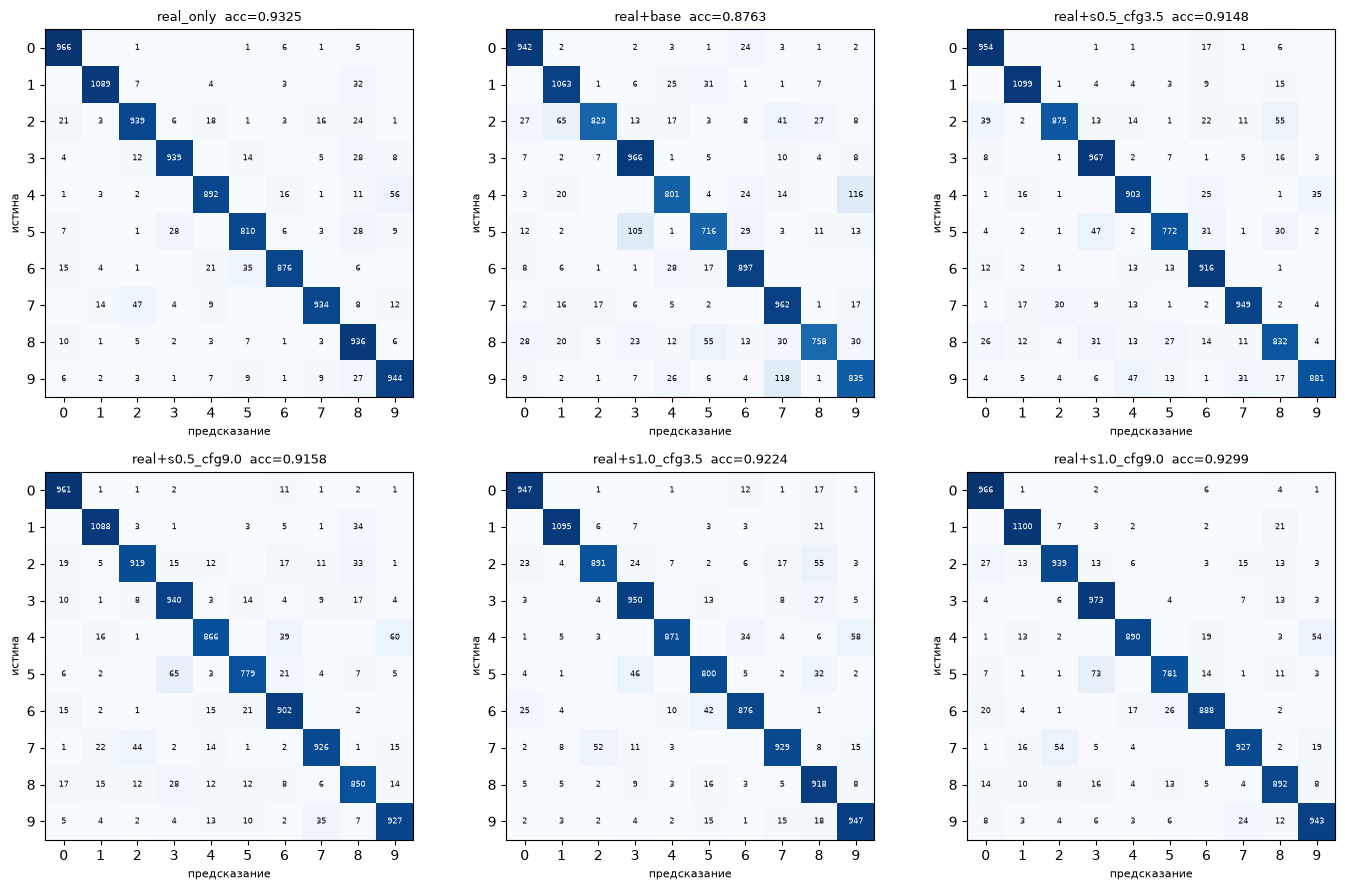

вариант,n test,верно,accuracy,ДИ 95% от,ДИ 95% до,Δ к real_only,исправил,испортил,p McNemar
real_only,10000,9325,0.9325,0.9274,0.9373,0.0000,0,0,1.0000
real+base,10000,8763,0.8763,0.8697,0.8826,-0.0562,174,736,0.0000
real+s0.5_cfg3.5,10000,9148,0.9148,0.9092,0.9201,-0.0177,215,392,0.0000
real+s0.5_cfg9.0,10000,9158,0.9158,0.9102,0.9211,-0.0167,187,354,0.0000
real+s1.0_cfg3.5,10000,9224,0.9224,0.9170,0.9275,-0.0101,139,240,0.0000
real+s1.0_cfg9.0,10000,9299,0.9299,0.9247,0.9347,-0.0026,163,189,0.1826


цифра,real_only,real+base,real+s0.5_cfg3.5,real+s0.5_cfg9.0,real+s1.0_cfg3.5,real+s1.0_cfg9.0
0,0.986,0.961,0.973,0.981,0.966,0.986
1,0.959,0.937,0.968,0.959,0.965,0.969
2,0.910,0.797,0.848,0.891,0.863,0.910
3,0.930,0.956,0.957,0.931,0.941,0.963
4,0.908,0.816,0.920,0.882,0.887,0.906
5,0.908,0.803,0.865,0.873,0.897,0.876
6,0.914,0.936,0.956,0.942,0.914,0.927
7,0.909,0.936,0.923,0.901,0.904,0.902
8,0.961,0.778,0.854,0.873,0.943,0.916
9,0.936,0.828,0.873,0.919,0.939,0.935


цифра,real+base,real+s0.5_cfg3.5,real+s0.5_cfg9.0,real+s1.0_cfg3.5,real+s1.0_cfg9.0
0,-0.024,-0.012,-0.005,-0.019,0.000
1,-0.023,0.009,-0.001,0.005,0.010
2,-0.112,-0.062,-0.019,-0.047,0.000
3,0.027,0.028,0.001,0.011,0.034
4,-0.093,0.011,-0.026,-0.021,-0.002
5,-0.105,-0.043,-0.035,-0.011,-0.033
6,0.022,0.042,0.027,0.000,0.013
7,0.027,0.015,-0.008,-0.005,-0.007
8,-0.183,-0.107,-0.088,-0.018,-0.045
9,-0.108,-0.062,-0.017,0.003,-0.001


вариант,test acc,Δ к real_only,p McNemar,Edge F1,CLIP cos,CLIP digit acc,pixel L1 div,CLIP dist div
real+base,0.8763,-0.0562,0.0000,0.0933,0.3140,0.1150,0.2196,0.1923
real+s0.5_cfg3.5,0.9148,-0.0177,0.0000,0.3507,0.2964,0.2050,0.1443,0.2119
real+s0.5_cfg9.0,0.9158,-0.0167,0.0000,0.4499,0.3162,0.2850,0.1969,0.1973
real+s1.0_cfg3.5,0.9224,-0.0101,0.0000,0.7370,0.2763,0.2250,0.1135,0.1695
real+s1.0_cfg9.0,0.9299,-0.0026,0.1826,0.8740,0.2956,0.3100,0.1390,0.1665


сохранено: artifacts\lab14\test_metrics.json | artifacts\lab14\per_class_accuracy.csv | artifacts\lab14\confusion_matrices | artifacts\lab14\confusion_matrices.png


In [11]:
# Задание 10. Сравнение на реальном test
# Все варианты задания 9 оцениваются на одном и том же независимом real test (официальный MNIST test).
# Сохраняются: общая точность с 95% ДИ, точность по классам, confusion matrices и попарное сравнение
# с real_only (McNemar — тот же test, поэтому сравнение парное).
from scipy.stats import binomtest

CM_DIR = ARTIFACTS / 'confusion_matrices'
CM_DIR.mkdir(parents=True, exist_ok=True)
variant_names = list(MODELS)

def wilson_ci(k, n, z=1.96):
    p = k / n
    centre = (p + z * z / (2 * n)) / (1 + z * z / n)
    half = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / (1 + z * z / n)
    return centre - half, centre + half

PREDS, CMS, rows = {}, {}, []
y_true = TEST_Y.numpy()
for name in variant_names:
    acc, preds = evaluate(MODELS[name], TEST_X, TEST_Y)
    PREDS[name] = preds.numpy()
    cm = np.zeros((N_CLASSES, N_CLASSES), dtype=int)
    np.add.at(cm, (y_true, PREDS[name]), 1)
    CMS[name] = cm
    assert cm.sum() == len(TEST_Y) and np.isclose(np.trace(cm) / cm.sum(), acc)
    pd.DataFrame(cm, index=[f'true_{c}' for c in range(N_CLASSES)],
                 columns=[f'pred_{c}' for c in range(N_CLASSES)]).to_csv(CM_DIR / f'cm_{name}.csv')
    k = int(np.trace(cm))
    lo, hi = wilson_ci(k, len(y_true))
    rows.append({'variant': name, 'n_test': len(y_true), 'correct': k, 'accuracy': acc, 'ci_low': lo, 'ci_high': hi})

TEST_RESULTS = pd.DataFrame(rows)
base_ok = PREDS['real_only'] == y_true
paired = []
for name in variant_names:
    ok = PREDS[name] == y_true
    fixed, broken = int((ok & ~base_ok).sum()), int((~ok & base_ok).sum())   # несогласные пары с real_only
    p = 1.0 if fixed + broken == 0 else binomtest(fixed, fixed + broken, 0.5).pvalue
    paired.append({'delta_vs_real': float(ok.mean() - base_ok.mean()), 'fixed': fixed, 'broken': broken, 'mcnemar_p': p})
TEST_RESULTS = pd.concat([TEST_RESULTS, pd.DataFrame(paired)], axis=1)

# Точность по классам: recall каждой цифры = диагональ / сумма строки
PER_CLASS_ACC = pd.DataFrame({name: np.diag(CMS[name]) / CMS[name].sum(1) for name in variant_names},
                             index=pd.Index(range(N_CLASSES), name='label'))
PER_CLASS_DELTA = PER_CLASS_ACC.sub(PER_CLASS_ACC['real_only'], axis=0).drop(columns='real_only')
PER_CLASS_ACC.to_csv(ARTIFACTS / 'per_class_accuracy.csv')
pd.DataFrame({'test_index': TEST_IDX, 'label': y_true, **{f'pred_{n}': PREDS[n] for n in variant_names}}) \
  .to_csv(ARTIFACTS / 'test_predictions.csv', index=False)

# Связь качества синтетики (задания 5–6) с пользой для классификатора
quality = (summary[['edge_f1', 'clip_prompt_cos', 'clip_digit_acc']]
           .join(div_summary.set_index('setting')[['pixel_l1', 'clip_dist']]))
quality.index = [f'real+{s}' for s in quality.index]
SYN_VS_DOWNSTREAM = TEST_RESULTS.set_index('variant')[['accuracy', 'delta_vs_real', 'mcnemar_p']].join(quality, how='inner')

save_json('test_metrics.json', {
    'test': {'source': 'официальный MNIST test', 'n': len(y_true), 'same_for_all_variants': True,
             'used_for_selection': False},
    'overall': TEST_RESULTS.to_dict(orient='records'),
    'per_class_accuracy': PER_CLASS_ACC.round(4).reset_index().to_dict(orient='records'),
    'confusion_matrices': {n: CMS[n].tolist() for n in variant_names},
    'synthetic_quality_vs_downstream': SYN_VS_DOWNSTREAM.round(4).reset_index().to_dict(orient='records'),
    'notes': {'ci': 'Wilson 95%', 'mcnemar': 'точный биномиальный тест по несогласным парам с real_only',
              'fixed': 'test-примеры, верные у варианта и неверные у real_only', 'broken': 'наоборот'},
})

# Confusion matrices: доли по строкам (recall), в ячейках — число примеров
fig, axes = plt.subplots(2, 3, figsize=(14, 9))
for ax, name in zip(axes.ravel(), variant_names):
    cm = CMS[name]
    ax.imshow(cm / cm.sum(1, keepdims=True), cmap='Blues', vmin=0, vmax=1)
    for t in range(N_CLASSES):
        for p_ in range(N_CLASSES):
            if cm[t, p_]:
                ax.text(p_, t, cm[t, p_], ha='center', va='center', fontsize=6,
                        color='white' if cm[t, p_] / cm[t].sum() > 0.5 else 'black')
    acc = TEST_RESULTS.set_index('variant').loc[name, 'accuracy']
    ax.set_title(f'{name}  acc={acc:.4f}', fontsize=9)
    ax.set_xticks(range(N_CLASSES)); ax.set_yticks(range(N_CLASSES))
    ax.set_xlabel('предсказание', fontsize=8); ax.set_ylabel('истина', fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'confusion_matrices.png', dpi=110); plt.show()

show_table(TEST_RESULTS.rename(columns={
    'variant': 'вариант', 'n_test': 'n test', 'correct': 'верно', 'accuracy': 'accuracy', 'ci_low': 'ДИ 95% от',
    'ci_high': 'ДИ 95% до', 'delta_vs_real': 'Δ к real_only', 'fixed': 'исправил', 'broken': 'испортил',
    'mcnemar_p': 'p McNemar'}),
    'Точность на реальном test (одинаковый test для всех вариантов)', digits=4, bold_max=('accuracy',))

show_table(PER_CLASS_ACC.reset_index().rename(columns={'label': 'цифра'}),
           'Точность по классам (recall цифры на real test)', gradient=(float(PER_CLASS_ACC.min().min()), 1.0))
m = float(PER_CLASS_DELTA.abs().max().max()) or 0.01
show_table(PER_CLASS_DELTA.reset_index().rename(columns={'label': 'цифра'}),
           'Δ точности по классам относительно real_only (зелёный — лучше, красный — хуже)', gradient=(-m, m))
show_table(SYN_VS_DOWNSTREAM.reset_index().rename(columns={
    'variant': 'вариант', 'accuracy': 'test acc', 'delta_vs_real': 'Δ к real_only', 'mcnemar_p': 'p McNemar',
    'edge_f1': 'Edge F1', 'clip_prompt_cos': 'CLIP cos', 'clip_digit_acc': 'CLIP digit acc',
    'pixel_l1': 'pixel L1 div', 'clip_dist': 'CLIP dist div'}),
    'Качество синтетики (задания 5–6) и польза для классификатора', digits=4)
print('сохранено:', ARTIFACTS / 'test_metrics.json', '|', ARTIFACTS / 'per_class_accuracy.csv', '|', CM_DIR,
      '|', ARTIFACTS / 'confusion_matrices.png')

### Задание 11. Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

#### Гипотеза (сформулирована до запуска абляции)

**Наблюдение из основного эксперимента.** Промпт просил «white chalk on a black background», но в задании 8 при scale 1.0 у 65–72% генераций фон оказался светлым (понадобилась инверсия), а на многих картинках видна текстура доски/бумаги. Стиль задаёт именно текст: контур отвечает только за геометрию.

**Гипотеза.** Стилевая часть промпта («chalk») уводит синтетику от домена MNIST. Если заменить её нейтральным MNIST-подобным описанием, то при тех же контурах, seed, scale, CFG, числе шагов и бюджете обучения:
1. доля генераций со светлым фоном (инвертированных) уменьшится;
2. edge precision вырастет (меньше лишних краёв от текстуры);
3. **основной критерий:** val accuracy варианта real+synthetic вырастет относительно той же настройки с исходным промптом.

**Один изменяемый фактор** — текст позитивного промпта:

| | промпт |
|---|---|
| основной | `a white handwritten digit {label} written with chalk on a black background, centered` |
| абляция | `a white handwritten digit {label} on a plain black background, flat, high contrast, no texture` |

Всё остальное фиксировано: те же 200 контуров и `gen_seed`, тот же негативный промпт, scale, CFG, `NUM_STEPS`, разрешение; для CNN — тот же `cnn_init.pt`, 500 шагов, batch, lr.

**Выбор настройки без test.** Абляция проводится для настройки со scale > 0, у которой лучшая **val** accuracy в задании 9.

**Шум выборки.** CNN обучается для обоих вариантов на 3 расписаниях seed (порядок батчей и dropout); сравниваются среднее и разброс. Повтор с seed 0 совпадает с запуском задания 9 — это проверка воспроизводимости.

**Решение принимается по валидации.** Test оценивается один раз в конце только для отчёта.

**Задание 11. Творческое мини-исследование**

- **Что делали**: для лучшей по val настройки `s1.0_cfg9.0` заменили стилевую часть промпта («chalk» → «plain …, no texture»), сгенерировали 200 картинок на тех же контурах и seeds, обучили CNN на 3 seeds для обоих промптов.
- **Зачем**: проверить гипотезу, что стиль промпта уводит синтетику от домена MNIST.
- **Результат**: `ablation_summary.json`, `ablation_rows.csv`, `ablation_preview.png`; генерация 12.4 мин; Edge F1 0.874 → 0.931, светлых фонов 65 % → 72 %, CLIP div 0.167 → 0.130; val 0.9293 → 0.9260 (Δ −0.003 ± 0.013) — гипотеза не подтвердилась; seed 0 воспроизвёл val задания 9 (0.937).

абляция для настройки (по val): s1.0_cfg9.0 {'setting': 's1.0_cfg9.0', 'control_scale': 1.0, 'cfg': 9.0}
генерация абляции: 200 изображений, 0 s в этом запуске


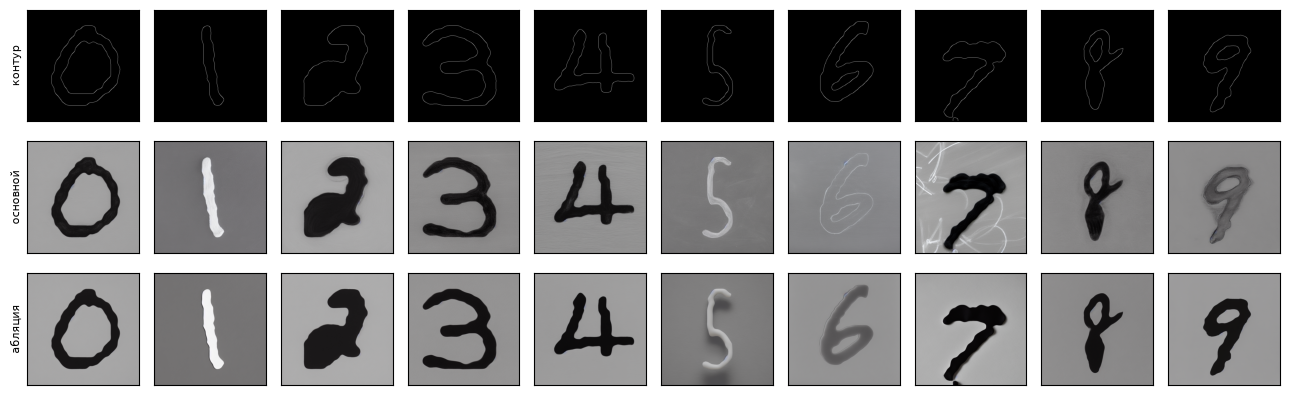

вариант,доля светлых фонов,Edge P,Edge R,Edge F1,CLIP cos (осн. промпт),CLIP digit acc,CLIP div
main_prompt,0.6500,0.9405,0.8677,0.8740,0.2956,0.3100,0.1665
ablation_prompt,0.7200,0.9700,0.9144,0.9312,0.2750,0.3150,0.1301
Δ (абляция − основной),0.0700,0.0295,0.0468,0.0572,-0.0206,0.0050,-0.0365
SE парной Δ,0.0207,0.0127,0.0191,0.0170,0.0021,0.0358,0.0023


seed обучения,val acc: основной,val acc: абляция,Δ val
0,0.9370,0.9190,-0.0180
1,0.9210,0.9290,0.0080
2,0.9300,0.9300,0.0000
среднее,0.9293,0.9260,-0.0033


критерий гипотезы,выполнен
меньше светлых фонов (inverted ↓),нет
выше edge precision,да
выше val accuracy (среднее по seeds),нет
val Δ > 0 на каждом seed,нет


seed обучения,test: основной,test: абляция,Δ test
0,0.9299,0.9202,-0.0097
1,0.9151,0.9262,0.0111
2,0.9259,0.9273,0.0014


{'setting': 's1.0_cfg9.0', 'reproducibility_seed0': {'task9': 0.937, 'now': 0.937}}
сохранено: artifacts\lab14\ablation_summary.json | artifacts\lab14\ablation_rows.csv | data\lab14\synthetic\r512_steps20\ablation_prompt_s1.0_cfg9.0


In [12]:
# Задание 11. Творческое мини-исследование: абляция стилевой части промпта
# Один фактор — текст позитивного промпта. Контуры, gen_seed, негативный промпт, scale, CFG, шаги,
# разрешение и бюджет CNN — как в основном эксперименте. Решение — по валидации; test — только для отчёта.
ABL_PROMPT = 'a white handwritten digit {label} on a plain black background, flat, high contrast, no texture'
ABL_TRAIN_SEEDS = [0] if FAST_DEV_RUN else [0, 1, 2]

# Настройка для абляции: лучшая val accuracy среди вариантов с контролем (задание 9), test не используется
controlled_info = TRAIN_INFO[TRAIN_INFO['variant'].str.startswith('real+') & (TRAIN_INFO['variant'] != 'real+base')]
ABL_BASE = controlled_info.sort_values('val_acc_final', ascending=False)['variant'].iloc[0].removeprefix('real+')
abl_cfg = next(st for st in SETTINGS if st['setting'] == ABL_BASE)
print('абляция для настройки (по val):', ABL_BASE, abl_cfg)

# --- 1. Генерация с новым промптом: те же контуры и seeds, отдельная папка и манифест, с возобновлением ---
ABL_DIR = SYNTH_DIR / f'r{RESOLUTION}_steps{NUM_STEPS}' / f'ablation_prompt_{ABL_BASE}'
ABL_MANIFEST = ARTIFACTS / 'ablation_synthetic.jsonl'
abl_done = {r['control_id']: r for r in read_jsonl(ABL_MANIFEST)
            if Path(r['image_png']).exists() and r['setting'] == ABL_BASE and r['resolution'] == RESOLUTION
            and r['steps'] == NUM_STEPS and r['prompt_template'] == ABL_PROMPT}
t_abl = time.time()
with open(ABL_MANIFEST, 'a', encoding='utf-8') as manifest:
    for row in CONTROLS:
        if row['control_id'] in abl_done:
            continue
        out_path = ABL_DIR / f"{row['control_id']}.png"
        out_path.parent.mkdir(parents=True, exist_ok=True)
        torch.cuda.synchronize(); t0 = time.time()
        img = generate(row['control_png'], ABL_PROMPT.format(label=row['label']), row['gen_seed'],
                       abl_cfg['control_scale'], abl_cfg['cfg'], negative_prompt=NEGATIVE_PROMPT)
        torch.cuda.synchronize()
        img.save(out_path)
        rec = {'control_id': row['control_id'], 'source_index': row['source_index'], 'label': row['label'],
               'setting': ABL_BASE, 'control_scale': abl_cfg['control_scale'], 'cfg': abl_cfg['cfg'],
               'seed': row['gen_seed'], 'prompt_template': ABL_PROMPT, 'prompt': ABL_PROMPT.format(label=row['label']),
               'negative_prompt': NEGATIVE_PROMPT, 'control_png': row['control_png'], 'image_png': out_path.as_posix(),
               'resolution': RESOLUTION, 'steps': NUM_STEPS, 'seconds': round(time.time() - t0, 3)}
        manifest.write(json.dumps(rec, ensure_ascii=False) + '\n'); manifest.flush()
        abl_done[row['control_id']] = rec
print(f'генерация абляции: {len(abl_done)} изображений, {time.time() - t_abl:.0f} s в этом запуске')

ABL = pd.DataFrame([abl_done[r['control_id']] for r in CONTROLS])
MAIN = METRICS[METRICS['setting'] == ABL_BASE].set_index('control_id').loc[ABL['control_id']].reset_index()
# Контролируемость: те же контуры, seeds, метки, scale, CFG; различается только промпт
assert (ABL['seed'].values == MAIN['seed'].values).all() and (ABL['label'].values == MAIN['label'].values).all()
assert (ABL['control_png'].values == MAIN['control_png'].values).all()
assert (MAIN['control_scale'] == abl_cfg['control_scale']).all() and (MAIN['cfg'] == abl_cfg['cfg']).all()

# --- 2. Метрики изображений теми же функциями, что в заданиях 5, 6, 8 ---
def image_metrics(paths, control_pngs, labels):
    rows = []
    for path, ctrl in zip(paths, control_pngs):
        p, r, f1 = edge_f1(edges_of_generated(path), np.array(Image.open(ctrl).convert('L')) > 0)
        _, inverted = to_mnist(path)
        rows.append({'edge_precision': p, 'edge_recall': r, 'edge_f1': f1, 'inverted': inverted})
    out = pd.DataFrame(rows)
    feats = clip_image_features(list(paths))
    main_prompts = clip_text_features([PROMPT.format(label=l) for l in labels])
    out['clip_cos_main_prompt'] = (feats * main_prompts).sum(1).cpu().numpy()   # общий эталон текста для обоих вариантов
    digit_pred = (feats @ clip_text_features(digit_texts).T).argmax(1).cpu().numpy()
    out['clip_digit_correct'] = digit_pred == np.asarray(labels)
    sims = (feats @ feats.T).cpu().numpy()
    lab = np.asarray(labels)
    out['clip_div'] = [float((1 - sims[i, (lab == lab[i]) & (np.arange(len(lab)) != i)]).mean()) for i in range(len(lab))]
    return out

m_main = image_metrics(MAIN['image_png'], MAIN['control_png'], MAIN['label'])
m_abl = image_metrics(ABL['image_png'], ABL['control_png'], ABL['label'])
ABL_ROWS = pd.concat([MAIN[['control_id', 'label', 'seed', 'image_png']].join(m_main).assign(variant='main_prompt'),
                      ABL[['control_id', 'label', 'seed', 'image_png']].join(m_abl).assign(variant='ablation_prompt')])
ABL_ROWS.to_csv(ARTIFACTS / 'ablation_rows.csv', index=False)

img_cols = ['inverted', 'edge_precision', 'edge_recall', 'edge_f1', 'clip_cos_main_prompt', 'clip_digit_correct', 'clip_div']
img_cmp = ABL_ROWS.groupby('variant')[img_cols].mean().reindex(['main_prompt', 'ablation_prompt'])
diff = (m_abl[img_cols].astype(float) - m_main[img_cols].astype(float))   # парные разности по одному контуру
img_cmp.loc['Δ (абляция − основной)'] = diff.mean()
img_cmp.loc['SE парной Δ'] = diff.std(ddof=1) / np.sqrt(len(diff))

# --- 3. Downstream: тот же бюджет, 3 расписания seed для обоих вариантов, решение по val ---
syn_abl = torch.from_numpy(np.stack([to_mnist(p)[0] for p in ABL['image_png']])).unsqueeze(1)
syn_main = torch.from_numpy(np.stack([to_mnist(p)[0] for p in MAIN['image_png']])).unsqueeze(1)
y_syn = torch.from_numpy(ABL['label'].to_numpy()).long()
abl_variants = {'main_prompt': (torch.cat([REAL_TRAIN_X, syn_main]), torch.cat([REAL_TRAIN_Y, y_syn])),
                'ablation_prompt': (torch.cat([REAL_TRAIN_X, syn_abl]), torch.cat([REAL_TRAIN_Y, y_syn]))}

def train_with_seeds(name, x, y, k):
    saved = dict(DOWNSTREAM)
    DOWNSTREAM.update(model_seed=SEED + 100 * k, batch_seed=SEED + 1 + 100 * k)   # k = 0 — как в задании 9
    try:
        return train_variant(f'abl_{name}_seed{k}', x, y)
    finally:
        DOWNSTREAM.clear(); DOWNSTREAM.update(saved)

abl_runs, ABL_MODELS = [], {}
for k in ABL_TRAIN_SEEDS:
    for name, (x, y) in abl_variants.items():
        model, info, _ = train_with_seeds(name, x, y, k)
        ABL_MODELS[(name, k)] = model.eval()
        abl_runs.append({'variant': name, 'train_seed': k, 'updates': info['updates'],
                         'samples_seen': info['samples_seen'], 'val_acc': info['val_acc_final']})
ABL_RUNS = pd.DataFrame(abl_runs)
assert ABL_RUNS['updates'].nunique() == 1 and ABL_RUNS['samples_seen'].nunique() == 1, 'бюджет различается'

val_pivot = ABL_RUNS.pivot(index='train_seed', columns='variant', values='val_acc')[['main_prompt', 'ablation_prompt']]
val_delta = val_pivot['ablation_prompt'] - val_pivot['main_prompt']
repro_val = float(TRAIN_INFO.set_index('variant').loc[f'real+{ABL_BASE}', 'val_acc_final'])

# Заранее заданные критерии гипотезы — проверяются только на val и метриках изображений
checks = {
    'меньше светлых фонов (inverted ↓)': bool(img_cmp.loc['Δ (абляция − основной)', 'inverted'] < 0),
    'выше edge precision': bool(img_cmp.loc['Δ (абляция − основной)', 'edge_precision'] > 0),
    'выше val accuracy (среднее по seeds)': bool(val_delta.mean() > 0),
    'val Δ > 0 на каждом seed': bool((val_delta > 0).all()),
}

# Test — один раз, после решения, только для отчёта
test_rows = []
for (name, k), model in ABL_MODELS.items():
    acc, _ = evaluate(model, TEST_X, TEST_Y)
    test_rows.append({'variant': name, 'train_seed': k, 'test_acc': acc})
ABL_TEST = pd.DataFrame(test_rows).pivot(index='train_seed', columns='variant', values='test_acc')[['main_prompt', 'ablation_prompt']]

save_json('ablation_summary.json', {
    'hypothesis': 'нейтральный MNIST-подобный промпт вместо «chalk» уменьшает долю светлых фонов, повышает edge '
                  'precision и val accuracy real+synthetic при прочих равных',
    'factor': {'main_prompt': PROMPT, 'ablation_prompt': ABL_PROMPT},
    'fixed': {'setting': ABL_BASE, **abl_cfg, 'negative_prompt': NEGATIVE_PROMPT, 'steps': NUM_STEPS,
              'resolution': RESOLUTION, 'seeds': 'gen_seed контуров', 'downstream': DOWNSTREAM},
    'setting_selection': 'лучшая val accuracy среди scale > 0 в задании 9 (test не использовался)',
    'image_metrics': img_cmp.round(4).reset_index().to_dict(orient='records'),
    'val_by_seed': val_pivot.round(4).reset_index().to_dict(orient='records'),
    'val_delta': {'mean': float(val_delta.mean()), 'std': float(val_delta.std(ddof=1)) if len(val_delta) > 1 else None},
    'reproducibility': {'task9_val_acc': repro_val, 'seed0_main_val_acc': float(val_pivot.loc[0, 'main_prompt'])},
    'hypothesis_checks_val_only': checks,
    'test_report_only': ABL_TEST.round(4).reset_index().to_dict(orient='records'),
})

# Превью: один контур на класс — контур, основной промпт, абляция
show_ids = ABL.drop_duplicates('label').sort_values('label')['control_id'].tolist()
fig, axes = plt.subplots(3, N_CLASSES, figsize=(N_CLASSES * 1.3, 4.2))
by_main, by_abl = MAIN.set_index('control_id'), ABL.set_index('control_id')
for c, cid in enumerate(show_ids):
    for r, img in enumerate([by_main.loc[cid, 'control_png'], by_main.loc[cid, 'image_png'], by_abl.loc[cid, 'image_png']]):
        axes[r, c].imshow(Image.open(img)); axes[r, c].set_xticks([]); axes[r, c].set_yticks([])
for r, title in enumerate(['контур', 'основной', 'абляция']):
    axes[r, 0].set_ylabel(title, fontsize=8)
plt.tight_layout(); plt.savefig(ARTIFACTS / 'ablation_preview.png', dpi=110); plt.show()

show_table(img_cmp.reset_index().rename(columns={
    'variant': 'вариант', 'inverted': 'доля светлых фонов', 'edge_precision': 'Edge P', 'edge_recall': 'Edge R',
    'edge_f1': 'Edge F1', 'clip_cos_main_prompt': 'CLIP cos (осн. промпт)', 'clip_digit_correct': 'CLIP digit acc',
    'clip_div': 'CLIP div'}), f'Метрики изображений: {ABL_BASE}, {len(ABL)} пар по одним контурам и seeds', digits=4)
val_view = val_pivot.assign(delta=val_delta).reset_index()
val_view.loc[len(val_view)] = ['среднее', *val_view[['main_prompt', 'ablation_prompt', 'delta']].mean()]
show_table(val_view.astype({'train_seed': str}).rename(columns={
    'train_seed': 'seed обучения', 'main_prompt': 'val acc: основной', 'ablation_prompt': 'val acc: абляция',
    'delta': 'Δ val'}), 'Downstream на валидации (критерий решения), одинаковый бюджет', digits=4)
show_table(pd.DataFrame([(k, 'да' if v else 'нет') for k, v in checks.items()], columns=['критерий гипотезы', 'выполнен']),
           'Проверка гипотезы (только val и метрики изображений)')
show_table(ABL_TEST.assign(delta=ABL_TEST['ablation_prompt'] - ABL_TEST['main_prompt']).reset_index()
                   .astype({'train_seed': str}).rename(columns={'train_seed': 'seed обучения', 'main_prompt': 'test: основной',
                                                                'ablation_prompt': 'test: абляция', 'delta': 'Δ test'}),
           'Test — только для отчёта, в решении не участвовал', digits=4)
print({'setting': ABL_BASE, 'reproducibility_seed0': {'task9': round(repro_val, 4),
                                                      'now': round(float(val_pivot.loc[0, 'main_prompt']), 4)}})
print('сохранено:', ARTIFACTS / 'ablation_summary.json', '|', ARTIFACTS / 'ablation_rows.csv', '|', ABL_DIR)

## Анализ результатов

Сопоставьте конфигурации при одинаковых данных, seeds и бюджете. Приведите таблицу фактических метрик и времени, не менее пяти неудачных примеров с объяснением причин, ограничения и проверяемые выводы. Не подменяйте измерения утверждением об успешном запуске.

In [13]:
# Анализ результатов: сводная таблица фактических метрик и времени из сохранённых артефактов.
# Все конфигурации — одни и те же 200 контуров, gen_seed, CNN init и бюджет 500 шагов.
def load(name):
    return json.loads((ARTIFACTS / name).read_text(encoding='utf-8'))

grid_s = pd.DataFrame(load('grid_summary.json')['per_setting']).set_index('setting')
img_s = pd.DataFrame(load('metrics_summary.json')['per_setting']).set_index('setting')
div_s = pd.DataFrame(load('diversity_summary.json')['per_setting']).set_index('setting')
prep_s = pd.DataFrame(load('downstream_split.json')['synthetic']['stats']).set_index('setting')
train_s = pd.DataFrame(load('downstream_train.json')['variants']).set_index('variant')
test_s = pd.DataFrame(load('test_metrics.json')['overall']).set_index('variant')

rows = []
for variant in test_s.index:
    setting = variant.removeprefix('real+') if variant != 'real_only' else None
    row = {'вариант': variant}
    if setting:
        row.update({'scale': grid_s.loc[setting, 'control_scale'], 'CFG': grid_s.loc[setting, 'cfg'],
                    'ген., с/изобр.': grid_s.loc[setting, 'sec_mean'], 'ген., мин': grid_s.loc[setting, 'sec_total'] / 60,
                    'Edge F1': img_s.loc[setting, 'edge_f1'], 'CLIP cos': img_s.loc[setting, 'clip_prompt_cos'],
                    'CLIP digit acc': img_s.loc[setting, 'clip_digit_acc'], 'CLIP div': div_s.loc[setting, 'clip_dist'],
                    'L1 div': div_s.loc[setting, 'pixel_l1'], 'светлый фон': prep_s.loc[setting, 'inverted_share']})
    row.update({'CNN, с': train_s.loc[variant, 'seconds'], 'val acc': train_s.loc[variant, 'val_acc_final'],
                'test acc': test_s.loc[variant, 'accuracy'], 'Δ test': test_s.loc[variant, 'delta_vs_real'],
                'p McNemar': test_s.loc[variant, 'mcnemar_p']})
    rows.append(row)
FINAL = pd.DataFrame(rows)
FINAL.to_csv(ARTIFACTS / 'final_summary.csv', index=False)

abl = load('ablation_summary.json')
abl_img = pd.DataFrame(abl['image_metrics']).set_index('variant')
abl_val = pd.DataFrame(abl['val_by_seed']).set_index('train_seed')
abl_test = pd.DataFrame(abl['test_report_only']).set_index('train_seed')
ABL_FINAL = pd.DataFrame({
    'промпт': ['основной (chalk)', 'абляция (plain)'],
    'светлый фон': abl_img.loc[['main_prompt', 'ablation_prompt'], 'inverted'].values,
    'Edge F1': abl_img.loc[['main_prompt', 'ablation_prompt'], 'edge_f1'].values,
    'CLIP div': abl_img.loc[['main_prompt', 'ablation_prompt'], 'clip_div'].values,
    'val acc (ср. 3 seeds)': abl_val[['main_prompt', 'ablation_prompt']].mean().values,
    'val acc std': abl_val[['main_prompt', 'ablation_prompt']].std(ddof=1).values,
    'test acc (ср. 3 seeds)': abl_test[['main_prompt', 'ablation_prompt']].mean().values,
})

worst = pd.DataFrame(load('worst_cases.json')['worst_by_edge_f1'])
FAILS = worst[['control_id', 'label', 'setting', 'edge_precision', 'edge_recall', 'edge_f1',
               'gen_edge_fraction', 'pixel_std', 'clip_digit_pred', 'flags']]

abl_gen_min = sum(r['seconds'] for r in read_jsonl(ARTIFACTS / 'ablation_synthetic.jsonl')) / 60
timing = pd.DataFrame([
    ('генерация сетки (1000 изобр.)', grid_s['sec_total'].sum() / 60, 'мин'),
    ('генерация абляции (200 изобр.)', abl_gen_min, 'мин'),
    ('обучение CNN (6 вариантов задания 9)', train_s['seconds'].sum(), 'с'),
    ('загрузка SD1.5 + ControlNet', load('model_info.json')['load_seconds'], 'с'),
], columns=['этап', 'время', 'ед.'])

pd.set_option('styler.format.na_rep', '—')   # у real_only нет метрик синтетики
gen_cols = ['вариант', 'scale', 'CFG', 'ген., с/изобр.', 'ген., мин', 'Edge F1', 'CLIP cos', 'CLIP digit acc',
            'CLIP div', 'L1 div', 'светлый фон']
ds_cols = ['вариант', 'CNN, с', 'val acc', 'test acc', 'Δ test', 'p McNemar']
show_table(FINAL[FINAL['вариант'] != 'real_only'][gen_cols],
           'Сводная таблица 1: синтетика по настройкам (200 изображений на настройку)', bold_max=('Edge F1', 'CLIP cos'))
show_table(FINAL[ds_cols], 'Сводная таблица 2: downstream CNN, одинаковый бюджет (500 шагов, общий init)',
           digits=4, bold_max=('val acc', 'test acc'))
show_table(ABL_FINAL, f"Абляция промпта для {abl['fixed']['setting']} (решение по val; test — только отчёт)", digits=4)
show_table(FAILS.rename(columns={'control_id': 'контур', 'label': 'цифра', 'setting': 'настройка', 'edge_precision': 'Edge P',
                                 'edge_recall': 'Edge R', 'edge_f1': 'Edge F1', 'gen_edge_fraction': 'доля краёв',
                                 'pixel_std': 'pixel std', 'clip_digit_pred': 'CLIP цифра', 'flags': 'флаги'}),
           'Пять наихудших генераций (задание 7) — объяснение причин ниже', digits=4)
show_table(timing, 'Время этапов (измерено)', digits=1)
print('сохранено:', ARTIFACTS / 'final_summary.csv')

вариант,scale,CFG,"ген., с/изобр.","ген., мин",Edge F1,CLIP cos,CLIP digit acc,CLIP div,L1 div,светлый фон
real+base,0.000,7.500,3.664,12.215,0.093,0.314,0.115,0.192,0.220,0.235
real+s0.5_cfg3.5,0.500,3.500,3.661,12.202,0.351,0.296,0.205,0.212,0.144,0.495
real+s0.5_cfg9.0,0.500,9.000,3.659,12.197,0.450,0.316,0.285,0.197,0.197,0.500
real+s1.0_cfg3.5,1.000,3.500,3.658,12.195,0.737,0.276,0.225,0.170,0.114,0.650
real+s1.0_cfg9.0,1.000,9.000,3.660,12.200,0.874,0.296,0.310,0.167,0.139,0.650


вариант,"CNN, с",val acc,test acc,Δ test,p McNemar
real_only,2.9800,0.9390,0.9325,0.0000,1.0000
real+base,2.6700,0.8780,0.8763,-0.0562,0.0000
real+s0.5_cfg3.5,2.6700,0.9200,0.9148,-0.0177,0.0000
real+s0.5_cfg9.0,2.6300,0.9250,0.9158,-0.0167,0.0000
real+s1.0_cfg3.5,2.5800,0.9260,0.9224,-0.0101,0.0000
real+s1.0_cfg9.0,2.5900,0.9370,0.9299,-0.0026,0.1826


промпт,светлый фон,Edge F1,CLIP div,val acc (ср. 3 seeds),val acc std,test acc (ср. 3 seeds)
основной (chalk),0.6500,0.8740,0.1665,0.9293,0.0080,0.9236
абляция (plain),0.7200,0.9312,0.1301,0.9260,0.0061,0.9246


контур,цифра,настройка,Edge P,Edge R,Edge F1,доля краёв,pixel std,CLIP цифра,флаги
c0_08_i30709,0,s0.5_cfg3.5,0.0000,0.0000,0.0000,0.0000,13.0300,0,"low_precision, low_recall, no_edges"
c3_07_i27856,3,s0.5_cfg3.5,0.0000,0.0000,0.0000,0.0013,8.6900,2,"low_precision, low_recall, clip_wrong_digit"
c8_08_i19460,8,s1.0_cfg3.5,0.0000,0.0000,0.0000,0.0000,9.5600,2,"low_precision, low_recall, clip_wrong_digit, no_edges"
c2_10_i40369,2,s0.5_cfg3.5,0.0000,0.0000,0.0000,0.0001,28.6600,2,"low_precision, low_recall"
c5_15_i46895,5,s0.5_cfg3.5,0.0000,0.0000,0.0000,0.0000,28.8100,2,"low_precision, low_recall, clip_wrong_digit, no_edges"


этап,время,ед.
генерация сетки (1000 изобр.),61.0,мин
генерация абляции (200 изобр.),12.4,мин
обучение CNN (6 вариантов задания 9),16.1,с
загрузка SD1.5 + ControlNet,17.0,с


сохранено: artifacts\lab14\final_summary.csv


#### Выводы по измерениям (полный режим: 200 контуров × 5 настроек, 512 px, 20 шагов UniPC, RTX 3060)

Все числа взяты из сводных таблиц выше и файлов `artifacts/lab14/*.json`. Конфигурации сравниваются при одинаковых контурах, `gen_seed`, промпте, init CNN и бюджете 500 шагов.

**1. Синтетика не улучшила классификатор на реальном test.** `real_only` даёт 0.9325. Лучший вариант с синтетикой, `real+s1.0_cfg9.0`, даёт 0.9299: Δ = −0.26 п.п., p McNemar = 0.18, то есть отличие **не значимо**. Остальные варианты значимо хуже (p < 0.001): от −1.0 п.п. (`s1.0_cfg3.5`) до −5.6 п.п. (`base`, без контроля). Выбор по val и по test совпадает: `s1.0_cfg9.0` лучший среди вариантов с синтетикой в обоих.

**2. Польза синтетики следует за структурой, а не за CLIP.** Упорядочивание по Edge F1 (0.09 → 0.35 → 0.45 → 0.74 → 0.87) совпадает с упорядочиванием по test accuracy (0.876 → 0.915 → 0.916 → 0.922 → 0.930). CLIP cos так себя не ведёт: у `base` он **максимальный** (0.314), а downstream у него худший. CLIP плохо различает цифры даже на реальном MNIST: zero-shot accuracy 0.335. Поэтому CLIP score не подтверждает ни геометрию, ни класс.

**3. Компромисс «контур ↔ текст» в этой сетке слабее ожидаемого.** Scale определяет Edge F1 (0.35–0.45 при 0.5 против 0.74–0.87 при 1.0). Повышение CFG с 3.5 до 9.0 подняло **и** Edge F1, **и** CLIP cos при обоих scale: CFG 9.0 не хуже 3.5 ни по одной из двух метрик.

**4. Разнообразие.** Pixel L1 внутри класса при scale 1.0 близко к реальному MNIST (0.81–0.99× real): форма наследуется от контуров. CLIP dist в 4.5–5.8 раза выше реального: синтетика разнообразна по **стилю** (фон, материал, освещение), которого в MNIST нет. Для классификатора это скорее сдвиг домена, чем полезное разнообразие.

**5. Промпт не управляет цветом.** Промпт просил белую цифру на чёрном фоне, но при scale 1.0 у 65% генераций светлый фон и тёмная цифра; понадобилась инверсия (задание 8).

**6. По классам эффект неоднороден** (`s1.0_cfg9.0` против `real_only`): цифра 3 +3.4 п.п., 6 +1.3, 1 +1.0, а 8 −4.5, 5 −3.3. Итоговая Δ ≈ 0 — это сумма разнонаправленных изменений по классам.

**7. Абляция промпта (задание 11): гипотеза не подтвердилась.**
- **Основной критерий не выполнен:** val accuracy 0.9260 против 0.9293. Δ = −0.003 ± 0.013 (std по 3 seeds) — в пределах шума обучения.
- **Светлых фонов стало больше, а не меньше:** 0.72 против 0.65.
- Edge F1 вырос (0.931 против 0.874), CLIP-разнообразие упало (0.130 против 0.167).
- На превью видно, почему: при scale 1.0 и CFG 9.0 изображение почти полностью задаётся контуром и априорным «тёмные чернила на сером фоне». Слова о цвете и материале модель в основном игнорирует. Убранная текстура сделала края чище, но и картинки однообразнее. Эти два эффекта для CNN взаимно погасились: test 0.9246 против 0.9236 — только для отчёта, разница в пределах шума.
- Seed 0 воспроизвёл val задания 9 точно (0.937 = 0.937).

**Время.** Сетка — 61.0 мин (3.66 с/изображение, одинаково для всех настроек: при scale 0 ControlNet всё равно вычисляется). Абляция — 12.4 мин. Обучение каждой CNN — 2.6–3.4 с. Загрузка моделей — 10 с.

#### Неудачные примеры и причины (рисунок `worst_cases.png`, таблица выше)

1. **`c0_08_i30709`, 0, `s0.5_cfg3.5`, F1 = 0.** Форма нуля **воспроизведена**, но серым штрихом на сером фоне. Canny с порогами 100/200 не нашёл ни одного края (доля краёв = 0). Причина — **артефакт метрики** на низкоконтрастной генерации, а не потеря структуры.
2. **`c3_07_i27856`, 3, `s0.5_cfg3.5`, F1 = 0.** Модель нарисовала тонкие декоративные завитки, частично вне контура. При scale 0.5 и CFG 3.5 оба условия слабые, и SD «дорисовывает» своё. Края есть только по краям кадра, все вне допуска.
3. **`c8_08_i19460`, 8, `s1.0_cfg3.5`, F1 = 0.** Форма восьмёрки повторена точно, но это бледная объёмная фигура с мягкими краями. Canny краёв не нашёл: та же **метрическая** причина, что в №1, даже при полном scale.
4. **`c2_10_i40369`, 2, `s0.5_cfg3.5`, F1 = 0.** Контур **проигнорирован**: вместо двойки — постороннее светлое пятно-объект. Слабый контроль, генерация ушла в произвольную сцену.
5. **`c5_15_i46895`, 5, `s0.5_cfg3.5`, F1 = 0.** Контур **проигнорирован**: маленький предмет на градиентном фоне. Причина та же — слабый контроль и слабый CFG.

Четыре из пяти худших — настройка `s0.5_cfg3.5`, самая «слабая» по обоим условиям. Примеры №1 и №3 показывают, что Edge F1 = 0 не всегда означает потерянную форму (флаг `no_edges`).

#### Ограничения

- В задании 9 каждый вариант обучен на **одном** seed. В абляции разброс val по seeds — около 0.6–0.8 п.п., это сопоставимо с различиями между соседними настройками. McNemar учитывает шум test-выборки, но не шум обучения.
- Режим малых данных выбран намеренно: 200 реальных цифр, синтетика построена из **тех же** сцен. Результат не переносится на полный MNIST и на синтетику из новых контуров.
- Edge F1 зависит от фиксированных порогов Canny: низкоконтрастные генерации получают F1 = 0 (примеры №1 и №3).
- CLIP ViT-B/32 слабо различает цифры (0.335 на real), поэтому CLIP-метрики отражают в основном стиль.
- Полярность определяется эвристикой «рамка светлее центра»; бледные генерации со светлым фоном и светлой обводкой она не исправляет.
- Проверены один промпт, 20 шагов и 4 точки сетки; safety checker отключён (записано в `model_info.json`).
- Лицензии в `model_info.json` и `split.json` указаны по памяти — сверить с карточками моделей и источником MNIST.

#### Проверяемые выводы

- Для этого протокола синтетика ControlNet **не даёт** значимого прироста точности: лучший случай — Δ = −0.26 п.п., p = 0.18. Проверка: `test_metrics.json`.
- Downstream-польза монотонно растёт с Edge F1 и не следует за CLIP cos. Проверка: `final_summary.csv`.
- Без контроля (`base`) синтетика вредит сильнее всего: −5.6 п.п., p < 0.001.
- Нейтральный промпт не изменил downstream-качество в пределах шума 3 seeds. Проверка: `ablation_summary.json`.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.

In [14]:
# Требования к сдаче: конфигурация, версии, источники/лицензии, checkpoints, инвентарь артефактов.
# Перед сдачей: Restart Kernel -> Run All с FAST_DEV_RUN = False. Готовые генерации подхватываются с диска.
import sys, hashlib, platform, importlib.metadata as md

if FAST_DEV_RUN:
    print('ВНИМАНИЕ: FAST_DEV_RUN = True — это smoke-прогон, не результат для сдачи.')

def sha1(path):
    return hashlib.sha1(Path(path).read_bytes()).hexdigest()

def version(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return None

checkpoints = [{'file': p.relative_to(ARTIFACTS).as_posix(), 'mb': round(p.stat().st_size / 2**20, 2), 'sha1': sha1(p)}
               for p in sorted([INIT_CKPT, *CKPT_DIR.glob('*.pt')])]
artifact_files = [{'file': p.relative_to(ARTIFACTS).as_posix(), 'kb': round(p.stat().st_size / 1024, 1)}
                  for p in sorted(ARTIFACTS.rglob('*')) if p.is_file()]
REQUIRED = ['split.json', 'controls.jsonl', 'model_info.json', 'synthetic.jsonl', 'grid_summary.json',
            'metrics_per_image.csv', 'metrics_summary.json', 'diversity_summary.json', 'audit_rows.csv',
            'worst_cases.json', 'worst_cases.png', 'cnn_architecture.json', 'downstream_split.json',
            'downstream_train.json', 'test_metrics.json', 'per_class_accuracy.csv', 'final_summary.csv']
missing = [f for f in REQUIRED if not (ARTIFACTS / f).exists()]

run_info = {
    'fast_dev_run': FAST_DEV_RUN,
    'runtime_minutes_this_kernel': round((time.time() - NOTEBOOK_T0) / 60, 1),
    'hardware': {'gpu': torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
                 'vram_gb': round(VRAM_GB, 1), 'os': platform.platform()},
    'config': {'seed': SEED, 'resolution': RESOLUTION, 'steps': NUM_STEPS, 'dtype': str(DTYPE),
               'sequential_offload': SEQUENTIAL_OFFLOAD, 'per_class': PER_CLASS,
               'canny': {'low': CANNY_LOW, 'high': CANNY_HIGH, 'blur': BLUR_KSIZE, 'binarize_at': BINARIZE_AT},
               'prompt': PROMPT, 'negative_prompt': NEGATIVE_PROMPT, 'settings': SETTINGS,
               'edge_tol_px': EDGE_TOL, 'clip_model': CLIP_ID, 'downstream': DOWNSTREAM,
               'ablation_prompt': globals().get('ABL_PROMPT'), 'ablation_setting': globals().get('ABL_BASE')},  # бонус может быть пропущен
    'versions': {'python': sys.version.split()[0], 'torch': torch.__version__, 'cuda': torch.version.cuda,
                 **{pkg: version(pkg) for pkg in ('diffusers', 'transformers', 'accelerate', 'opencv-python-headless',
                                                  'numpy', 'pandas', 'scipy', 'pillow', 'matplotlib', 'torchvision')}},
    'sources_and_licenses': [
        {'item': 'MNIST (torchvision, официальные train/test)', 'license': 'CC BY-SA 3.0 — сверить с источником'},
        {'item': model_info['sd_model']['id'], 'revision': model_info['sd_model']['revision'],
         'license': 'CreativeML OpenRAIL-M — сверить с карточкой'},
        {'item': model_info['controlnet']['id'], 'revision': model_info['controlnet']['revision'],
         'license': 'OpenRAIL — сверить с карточкой'},
        {'item': CLIP_ID, 'license': 'MIT — сверить с карточкой'},
    ],
    'checkpoints': checkpoints,
    'data_files': {'controls_png': len(list(CONTROL_DIR.glob('ctrl_*.png'))),
                   'synthetic_png': len(list(SYNTH_DIR.rglob('*.png')))},
    'artifacts': artifact_files,
    'required_missing': missing,
}
save_json('run_info.json', run_info)

# Копия артефактов на постоянное хранилище (Google Drive в Colab), если задан путь CV_DRIVE_DIR
DRIVE_DIR = os.getenv('CV_DRIVE_DIR')
if DRIVE_DIR:
    shutil.copytree(ARTIFACTS, Path(DRIVE_DIR) / ARTIFACTS.name, dirs_exist_ok=True)
    print('скопировано в', Path(DRIVE_DIR) / ARTIFACTS.name)

show_table(pd.DataFrame([
    ('режим', 'FAST_DEV_RUN (smoke)' if FAST_DEV_RUN else 'полный'),
    ('время ядра, мин', run_info['runtime_minutes_this_kernel']),
    ('GPU', run_info['hardware']['gpu']),
    ('контуров / синтетических PNG', f"{run_info['data_files']['controls_png']} / {run_info['data_files']['synthetic_png']}"),
    ('файлов в artifacts', len(artifact_files)),
    ('обязательных файлов нет', ', '.join(missing) or '— все на месте'),
], columns=['параметр', 'значение']).astype({'значение': str}), 'Готовность к сдаче')
show_table(pd.DataFrame([(k, v) for k, v in run_info['versions'].items()], columns=['пакет', 'версия']).astype(str),
           'Версии библиотек')
show_table(pd.DataFrame(run_info['sources_and_licenses']).fillna('—'), 'Источники и лицензии')
show_table(pd.DataFrame(checkpoints), 'Checkpoints CNN', digits=2)
assert not missing, f'нет обязательных артефактов: {missing}'
print('сохранено:', ARTIFACTS / 'run_info.json')

параметр,значение
режим,полный
"время ядра, мин",3.4
GPU,NVIDIA GeForce RTX 3060
контуров / синтетических PNG,200 / 1200
файлов в artifacts,77
обязательных файлов нет,— все на месте


пакет,версия
python,3.12.1
torch,2.11.0+cu128
cuda,12.8
diffusers,0.41.0
transformers,5.17.0
accelerate,1.15.0
opencv-python-headless,5.0.0.93
numpy,2.5.3
pandas,3.0.5
scipy,1.18.1


item,license,revision
"MNIST (torchvision, официальные train/test)",CC BY-SA 3.0 — сверить с источником,—
stable-diffusion-v1-5/stable-diffusion-v1-5,CreativeML OpenRAIL-M — сверить с карточкой,451f4fe16113bff5a5d2269ed5ad43b0592e9a14
lllyasviel/sd-controlnet-canny,OpenRAIL — сверить с карточкой,7f2f69197050967007f6bbd23ab5e52f0384162a
openai/clip-vit-base-patch32,MIT — сверить с карточкой,—


file,mb,sha1
checkpoints/cnn_abl_ablation_prompt_seed0.pt,1.80,35f355109e20f73375beecaf55460e79c80dc4e2
checkpoints/cnn_abl_ablation_prompt_seed1.pt,1.80,6a7566a37d8b553bfa5ab6ebb8c9045a530c4d6f
checkpoints/cnn_abl_ablation_prompt_seed2.pt,1.80,118b00e8b0c05145b06d4805a5e461cb08b98c1f
checkpoints/cnn_abl_main_prompt_seed0.pt,1.80,5f90409b1e5584a4a3b7b0765e567666d70002e1
checkpoints/cnn_abl_main_prompt_seed1.pt,1.80,84fc3ee973390ac8f13aaa5a431aa0962f815833
checkpoints/cnn_abl_main_prompt_seed2.pt,1.80,39537685ed6bb65da9082fd9bdea547500803968
checkpoints/cnn_real+base.pt,1.80,61410f81105e9597ec47ad1c0b77c2e8b399dcac
checkpoints/cnn_real+s0.5_cfg3.5.pt,1.80,96da1ef542285912994e035c6ec186ded95271db
checkpoints/cnn_real+s0.5_cfg9.0.pt,1.80,e3672664e0c6babcbd125179807948fb7de082e2
checkpoints/cnn_real+s1.0_cfg3.5.pt,1.80,9aabcfa20cf84fc34675ec18539cc5b22df71946


сохранено: artifacts\lab14\run_info.json
